# סיווג משלחי יד מתוך נתוני סקר
### בקרת נתונים והשוואת שיטות ייצוג לצורך חיזוי משלח יד

**מטרת העבודה:** לפתח ולבחון תהליך לחיזוי `SemelMishlachSofi` על בסיס הנתונים והגדרות השדות שבקובץ המטלה. העבודה כוללת בדיקת כל 18 העמודות, אימות טיפוסים ותחומי ערכים מתוך גיליון `Metadata`, הכנת תכונות, השוואת שמונה ייצוגים והערכה קבוצתית שאינה מערבבת אימון ובדיקה.

**שיטות ההשוואה:** קידוד OneHot לערכי טקסט שלמים, TF-IDF תווי ישיר, שני ייצוגי מרחק אוקלידי, וארבע שיטות קיבוץ תיאורים. הקיבוץ משווה בין KMeans על TF-IDF צפוף לבין MiniBatchKMeans על TF-IDF דליל, עם החלקת IDF ובלעדיה. כל שורה לא ריקה מנורמלת ב-L2 לפני קיבוץ. מספר האשכולות נבחר לפי Calinski-Harabasz, והשיוך לאשכול מקודד כקטגוריה נומינלית באמצעות OneHotEncoder.

**מה משמעות הקרבה?** מרחק אוקלידי קטן בין וקטורי TF-IDF מנורמלים מעיד על דמיון בייצוג הלקסיקלי שנלמד מתוך טקסט האימון. אין בכך הוכחה שתיאורי משלח היד זהים במשמעותם המקצועית. לכן אנו מציגים הן מדדי הפרדה גאומטריים והן בדיקה מדגמית של חברי האשכולות.

**אימות:** משתמשים באותו מסווג ובאותם שדות נוספים לכל השיטות. התאמת הממירים והמודלים נעשית על נתוני האימון בלבד. בחירת השיטה נעשית באימות פנימי לפני בחינת קבוצת הבדיקה. נתוני המטלה מדמים סקרים, ולכן התוצאות אינן הערכת ביצועים על נתוני אמת.

**מקור הנתונים:** [DUMMY_DATASET.xlsx](https://github.com/shulruferor-sudo/Advance-Data-Science/tree/main/Datasets/cbs_occupation_survey_sample)

**קוד:** [GitHub](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/occupation_classification.ipynb) | [Google Colab](https://colab.research.google.com/github/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/occupation_classification.ipynb)


## 1. סביבת הרצה ושחזור
המחברת מורידה את קובץ ה-Excel הציבורי מ-GitHub ומאמתת את תוכנו באמצעות SHA-256. אפשר להפעיל אותה ב-Google Colab ללא הרשאות Drive. לצורך הרצה מקומית ניתן להגדיר את `CBS_OCCUPATION_WORKBOOK_PATH` כנתיב לקובץ זהה למקור.

In [1]:
from __future__ import annotations
import hashlib
import io
import os
import re
import sys
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import calinski_harabasz_score, precision_score, recall_score, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import euclidean_distances
from scipy.sparse import issparse
from time import perf_counter
import math
import warnings
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
# Approximate colors from the independently inspected portfolio homepage preview.
PALETTE = {"blue": "#16462E", "teal": "#729179", "gray": "#647368",
           "pale": "#E7ECE1", "orange": "#A38A61", "edge": "#355744"}
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 65)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.5 | pandas 2.2.3 | scikit-learn 1.8.0


## 2. טעינת שני הגיליונות לפי המבנה המקורי
קוראים תחילה את ארבע עמודות ההגדרה של `Metadata`, משום שבקובץ המקורי קיימת התפרסות עיצובית של הגיליון אל מעבר לשדות המידע. אחר כך משתמשים בטיפוסי המקור כדי לטעון במפורש את שדות `TEXT` כמחרוזות. קוד `123` נשאר `"123"` ואינו מושלם אוטומטית לארבע ספרות. שורת הסיכום היחידה ללא `ID` אינה משתתף ולכן מוצאת רק *ממערך הניתוח*, בלי לשנות את הקובץ המקורי.

In [2]:
SOURCE_URL = (
    "https://raw.githubusercontent.com/shulruferor-sudo/Advance-Data-Science/"
    "main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx"
)
EXPECTED_SHA256 = "e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac"
local_test_path = os.environ.get("CBS_OCCUPATION_WORKBOOK_PATH")
if local_test_path:
    excel_bytes = Path(local_test_path).read_bytes()
else:
    req = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "occupation-analysis"})
    with urllib.request.urlopen(req, timeout=60) as response:
        excel_bytes = response.read()
actual_hash = hashlib.sha256(excel_bytes).hexdigest()
assert actual_hash == EXPECTED_SHA256, (
    "Dataset version changed. Inspect Metadata and source rows before reporting results."
)
file = pd.ExcelFile(io.BytesIO(excel_bytes), engine="openpyxl")
assert set(file.sheet_names) == {"Survey Dataset", "Metadata"}
metadata = pd.read_excel(file, sheet_name="Metadata", usecols="A:D", dtype="string")
metadata.columns = metadata.columns.astype(str).str.strip()
meta_fields = ["משתנה", "הסבר", "פורמט", "ערכים אפשריים"]
assert metadata.columns.tolist() == meta_fields
metadata = metadata.loc[metadata["משתנה"].notna(), meta_fields].copy()
for c in ["משתנה", "פורמט"]:
    metadata[c] = metadata[c].str.strip()
assert metadata["משתנה"].is_unique
assert metadata["פורמט"].isin(["INTEGER", "TEXT", "DATE"]).all()
text_columns = metadata.loc[metadata["פורמט"].eq("TEXT"), "משתנה"].tolist()
raw_survey = pd.read_excel(file, sheet_name="Survey Dataset",
                           dtype={field: "string" for field in text_columns})
non_participant = raw_survey.loc[raw_survey["ID"].isna()].copy()
survey = raw_survey.loc[raw_survey["ID"].notna()].copy().reset_index(drop=True)
assert survey.shape == (200, 18)
assert metadata.shape == (18, 4)
assert set(survey.columns) == set(metadata["משתנה"])
assert len(non_participant) == 1
print("Workbook SHA-256:", actual_hash)
print("Survey records:", len(survey), "| Columns:", len(survey.columns),
      "| Metadata definitions:", len(metadata), "| Non-participant summary rows:", len(non_participant))
display(survey[["ID", "EzoAvoda", "SemelMishlachSofi"]].head(5))

Workbook SHA-256: e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac
Survey records: 200 | Columns: 18 | Metadata definitions: 18 | Non-participant summary rows: 1


,ID,EzoAvoda,SemelMishlachSofi
0,1.0,סגן מנהל אגף,2120
1,2.0,טכנאית רדיותרפיה,3311
2,3.0,נותנת תמיכה ללקוחות שמבקשים עזרה,3512
3,4.0,שומר בבית הספר,5414
4,5.0,מטפל בקשיש,5322


## 3. בדיקות המבוססות על הגדרות ה-Metadata
מנגנון הבדיקות קורא את השדות וההגדרות ישירות מגיליון `Metadata`. הוא אינו משתמש בעותק ידני של מילון שדות.

- `פורמט` קובע את בדיקות הטיפוס לכל עמודה.
- רשימה ממוספרת ב-`ערכים אפשריים` משמשת לבדיקת תחום קודים רק כאשר הרשימה אכן מופיעה במקור.
- הגדרה מפורשת של קוד בן ארבע ספרות משמשת לבדיקת אורך הקוד.
- סימון עמודה כמשתנה המטרה מונע שימוש בה כתכונת קלט.

**מגבלת הבדיקות:** טיפוס השדה אינו קובע שכל ערך חייב להיות מלא, שקוד מסוים הוא ערך תקין מבחינה מקצועית או שהשדה זמין בזמן החיזוי. המטלה מאפשרת שידור טפסים חלקיים. לפיכך יש להבחין בין ערך חסר לבין חריגה מהגדרה מפורשת.

In [3]:
def parse_enumerated_codes(raw):
    """Codes are extracted only from numbered lines explicitly supplied by Metadata."""
    if pd.isna(raw):
        return {}
    pairs = re.findall(r"(?m)^\s*(\d+)\.\s*(\S[^\n]*?)\s*$", str(raw))
    return {int(number): label.strip() for number, label in pairs}

def code_width_from_description(description):
    if pd.isna(description):
        return None
    match = re.search(r"מורכב\s*מ\s*[-־]?\s*(\d+)\s*ספרות", str(description))
    return int(match.group(1)) if match else None

contracts = metadata.set_index("משתנה", verify_integrity=True)
enumerations = {field: parse_enumerated_codes(contracts.loc[field, "ערכים אפשריים"])
                for field in survey.columns}
widths = {field: code_width_from_description(contracts.loc[field, "הסבר"])
          for field in survey.columns}
identified_targets = metadata.loc[
    metadata["ערכים אפשריים"].fillna("").str.contains("משתנה המטרה", regex=False), "משתנה"
].tolist()
assert identified_targets == ["SemelMishlachSofi"]
TARGET = identified_targets[0]
assert widths["SemelAnafSofi"] == widths[TARGET] == 4
print("Metadata type counts:", contracts["פורמט"].value_counts().to_dict())
print("Enumerations specified in source:", {k:len(v) for k,v in enumerations.items() if v})
print("Four-digit code fields:", [k for k,v in widths.items() if v==4])
for row_start in range(0,len(metadata),4):
    print(f"Metadata definitions {row_start+1}–{min(row_start+4,len(metadata))}")
    display(metadata.iloc[row_start:row_start+4][["משתנה","פורמט","הסבר"]].reset_index(drop=True))

Metadata type counts: {'TEXT': 10, 'INTEGER': 7, 'DATE': 1}
Enumerations specified in source: {'MenahelEtMi': 3, 'MaamadAvoda': 7, 'MakorSachar': 4, 'TeudaGvoha': 9}
Four-digit code fields: ['SemelAnafSofi', 'SemelMishlachSofi']
Metadata definitions 1–4


,משתנה,פורמט,הסבר
0,ID,INTEGER,מספר רץ
1,YeshuvAvoda,TEXT,שם יישוב עבודה
2,ShemAvoda,TEXT,שם מקום העבודה שלך
3,SugAvoda,TEXT,הפעילות העיקרית של מקום העבודה


Metadata definitions 5–8


,משתנה,פורמט,הסבר
0,ShemMachlaka,TEXT,אגף או מחלקה שהנסקר עובד
1,SugMachlaka,TEXT,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד
2,EzoAvoda,TEXT,עבודה שהנסקר עושה במקום עבודה זה
3,TeurPeula,TEXT,הפעולות העיקריות שהנסקר עושה במקום עבודה


Metadata definitions 9–12


,משתנה,פורמט,הסבר
0,TeurTafkid,TEXT,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה ויש)
1,MenahelEtMi,INTEGER,האם הנסקר מנהל או ממונה על עובדים אחרים?
2,MaamadAvoda,INTEGER,מעמד הנסקר במקום עבודה זה
3,MakorSachar,INTEGER,מקור השכר של הנסקר (השדה מלא רק במידה והנסקר שכיר או חבר קואו...


Metadata definitions 13–16


,משתנה,פורמט,הסבר
0,TeudaGvoha,INTEGER,התעודה או התואר הגבוה ביותר של הנסקר
1,shnotlimud,INTEGER,שנות הלימוד של הנסקר
2,Gil,INTEGER,גיל הנסקר
3,SemelAnafSofi,TEXT,סמל ענף כלכלי של מקום העבודה - מורכב מ-4 ספרות לפי תקן בינלאומי


Metadata definitions 17–18


,משתנה,פורמט,הסבר
0,TarichHathala,DATE,תאריך התחלת התפקיד
1,SemelMishlachSofi,TEXT,סמל משלח יד - מורכב מ-4 ספרות לפי תקן בינלאומי


## 4. מנוע הבדיקות: טיפוס השדה מפעיל את הבדיקות
`validate_type()` הוא פונקציית ניתוב לפי `פורמט`, שאינה מכילה רשימה ידנית של 18 תיאורי עמודות. כל תוצאה היא מסכת שורות המשויכת לשדה ולכלל המקור. הודעות חריגה אינן מוחקות ערכים ואינן מבצעות המרות שקטות.

**`INTEGER`:** זיהוי ערכים שאינם מספרים, שברים שאינם מספרים שלמים, והפרת רשימה ממוספרת אם קיימת במטא-דאטה. **`TEXT`:** טיפול באחסון כמחרוזת ובדיקת רוחב לקודים רק כאשר הוא מוצהר. **`DATE`:** זיהוי תאריכים שאי אפשר לפענח. לכל טיפוס נרשמים חסרים, שכיחויות ושונות כמדדי תיאור, ללא הנחת חובה למלא.

In [4]:
def occupied(series):
    return series.notna() & series.astype("string").str.strip().fillna("").ne("")

def validate_type(frame, field):
    """Return row-level masks. Source values are never changed."""
    kind = str(contracts.loc[field, "פורמט"])
    series = frame[field]
    nonempty = occupied(series)
    flags = {}
    if kind == "INTEGER":
        numeric = pd.to_numeric(series, errors="coerce")
        flags["non_numeric"] = nonempty & numeric.isna()
        flags["non_integral"] = (numeric.notna() & numeric.mod(1).ne(0)).fillna(False)
        if enumerations[field]:
            flags["outside_enumeration"] = (
                numeric.notna() & ~numeric.isin(enumerations[field])
            ).fillna(False)
    elif kind == "TEXT":
        if widths[field] is not None:
            text = series.astype("string").str.strip()
            pattern = rf"[0-9Xx]{{{widths[field]}}}"
            flags["code_shape_mismatch"] = (
                nonempty & ~text.str.fullmatch(pattern, na=False)
            ).fillna(False)
            flags["partial_X_code"] = (
                nonempty & text.str.fullmatch(pattern, na=False)
                & text.str.contains("X",case=False,regex=False,na=False)
            ).fillna(False)
    elif kind == "DATE":
        parsed = pd.to_datetime(series,errors="coerce",format="mixed")
        flags["unparseable_date"] = nonempty & parsed.isna()
    else:
        raise ValueError(f"Metadata type {kind!r} is unsupported; no silent fallback")
    return {rule: mask.astype(bool) for rule,mask in flags.items()}

source_issues = []
summary_rows = []
checklist_rows = []
for field in survey.columns:
    flags = validate_type(survey, field)
    is_present = occupied(survey[field])
    checks = ["presence", "type:"+contracts.loc[field,"פורמט"]]
    if enumerations[field]: checks.append("declared_domain")
    if widths[field]: checks.append("declared_code_width")
    for rule, mask in flags.items():
        if not mask.any() or rule=="partial_X_code": continue  # A partial code is a review status, not a type-contract violation.
        for idx in survey.index[mask]:
            source_issues.append({"ID": survey.loc[idx,"ID"], "field":field,
                                  "rule":rule, "original":str(survey.loc[idx,field]),
                                  "provenance":"Metadata: "+str(contracts.loc[field,"פורמט"])})
    populated = survey.loc[is_present,field].astype("string").str.strip()
    summary_rows.append({"field":field, "type":str(contracts.loc[field,"פורמט"]),
                         "missing":int((~is_present).sum()),
                         "missing_pct":round(float((~is_present).mean()*100),1),
                         "distinct_nonmissing":int(populated.nunique()),
                         "checks":", ".join(checks),
                         "violations":sum(int(mask.sum()) for rule,mask in flags.items()
                                          if rule!="partial_X_code"),
                         "X_partial":int(flags.get("partial_X_code",pd.Series(False,index=survey.index)).sum())})
    checklist_rows.append({"field":field,
        "presence":True,
        "integer":contracts.loc[field,"פורמט"]=="INTEGER",
        "text":contracts.loc[field,"פורמט"]=="TEXT",
        "date":contracts.loc[field,"פורמט"]=="DATE",
        "enumeration":bool(enumerations[field]),
        "code_width":widths[field] is not None})
summary=pd.DataFrame(summary_rows)
issues=pd.DataFrame(source_issues,columns=["ID","field","rule","original","provenance"])
checklist=pd.DataFrame(checklist_rows).set_index("field")
assert len(summary)==18 and checklist.shape==(18,6)
for start in range(0,len(summary),6):
    display(summary.iloc[start:start+6][["field","type","missing","missing_pct","violations","X_partial"]])
print("Source violations (excluding valid partial X labels):",len(issues))
print("Validation issues by rule:")
display(issues.groupby(["rule","field"]).size().rename("records").reset_index() if len(issues)
        else pd.DataFrame({"status":["No type-validation violations"]}))

,field,type,missing,missing_pct,violations,X_partial
0,ID,INTEGER,0,0.0,0,0
1,YeshuvAvoda,TEXT,0,0.0,0,0
2,ShemAvoda,TEXT,0,0.0,0,0
3,SugAvoda,TEXT,25,12.5,0,0
4,ShemMachlaka,TEXT,64,32.0,0,0
5,SugMachlaka,TEXT,134,67.0,0,0


,field,type,missing,missing_pct,violations,X_partial
6,EzoAvoda,TEXT,7,3.5,0,0
7,TeurPeula,TEXT,136,68.0,0,0
8,TeurTafkid,TEXT,172,86.0,0,0
9,MenahelEtMi,INTEGER,168,84.0,0,0
10,MaamadAvoda,INTEGER,2,1.0,0,0
11,MakorSachar,INTEGER,14,7.0,0,0


,field,type,missing,missing_pct,violations,X_partial
12,TeudaGvoha,INTEGER,2,1.0,0,0
13,shnotlimud,INTEGER,2,1.0,0,0
14,Gil,INTEGER,2,1.0,0,0
15,TarichHathala,DATE,0,0.0,0,0
16,SemelAnafSofi,TEXT,0,0.0,5,9
17,SemelMishlachSofi,TEXT,0,0.0,0,9


Source violations (excluding valid partial X labels): 5
Validation issues by rule:


,rule,field,records
0,code_shape_mismatch,SemelAnafSofi,5


## 5. בדיקות יחידה למנגנון האימות
הבדיקות מפעילות את כללי הטיפוס, תחום הקודים ומבנה הקוד על עותק זמני של הנתונים. כך ניתן לוודא שמנגנון הבדיקות מזהה ערכים שנוצרו לצורך בדיקה בלבד. המקור המקורי אינו משתנה.

In [5]:
def assert_detected(field, invalid, expected_rule):
    sample = survey[[field]].astype({field: "object"}).copy()
    sample.loc[0,field] = invalid
    observed = validate_type(sample,field)
    assert expected_rule in observed, (field,expected_rule)
    assert observed[expected_rule].iloc[0], (field,invalid,expected_rule)

assert_detected("shnotlimud", "not-an-integer", "non_numeric")
assert_detected("Gil", 31.5, "non_integral")
assert_detected("MaamadAvoda", 99, "outside_enumeration")
assert_detected("TarichHathala", "not-a-date", "unparseable_date")
assert_detected("SemelAnafSofi", "12", "code_shape_mismatch")
assert_detected("SemelMishlachSofi", "1X3X", "partial_X_code")
assert sum(int(m.sum()) for rule,m in validate_type(survey,"EzoAvoda").items())==0
print("6 mutated-input tests and 1 source-text control: PASSED")

6 mutated-input tests and 1 source-text control: PASSED


## 6. הפעלת בדיקות רוחב על כל השדות: תצוגה גרפית
מטריצת הפעלה מסבירה בדיוק מה מופעל אוטומטית עבור כל שדה. התרשימים נגזרים מן הטיפוסים והקודים שנמצאו ב-Metadata המקורי. הם אינם נתונים מיוצרים ואינם תחומי ערכים משוערים.

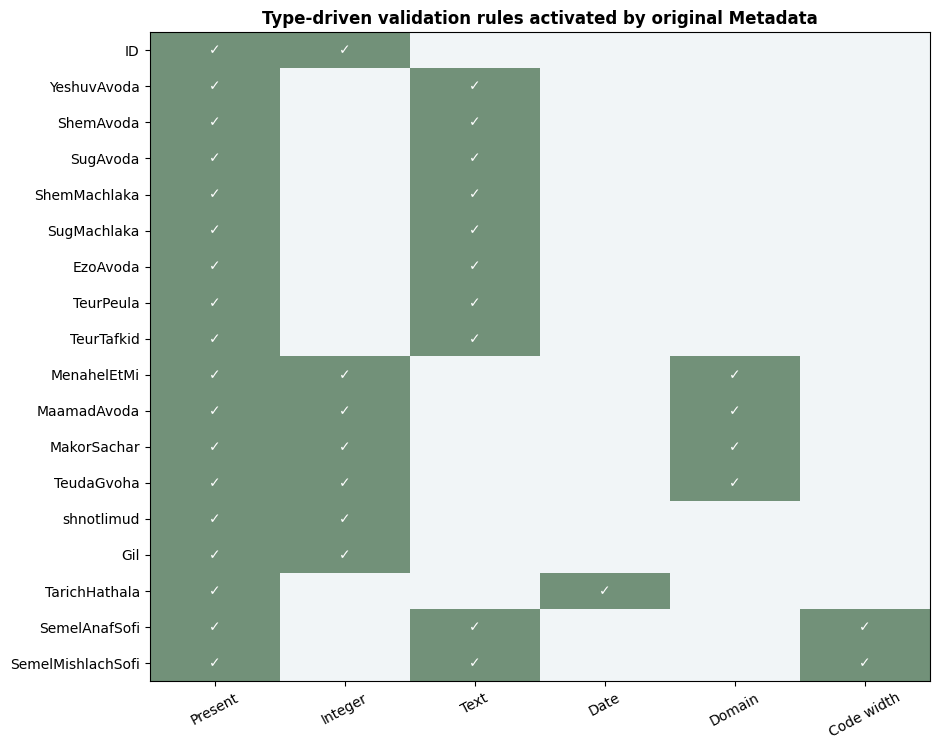

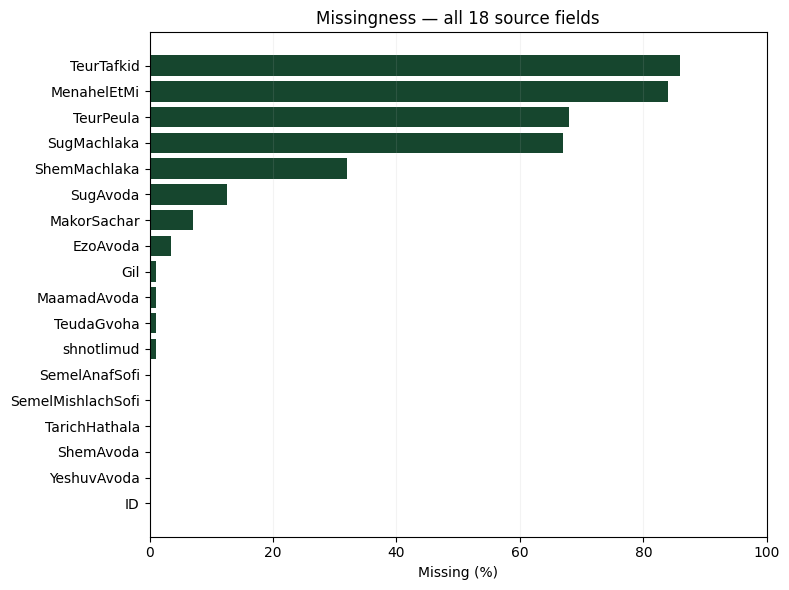

In [6]:
fig, ax = plt.subplots(figsize=(9.5,7.6))
ax.imshow(checklist.astype(int).values, aspect="auto",
          cmap=ListedColormap(["#F1F5F7",PALETTE["teal"]]), vmin=0,vmax=1)
ax.set_yticks(range(len(checklist.index)),labels=checklist.index)
ax.set_xticks(range(len(checklist.columns)),labels=["Present","Integer","Text","Date","Domain","Code width"])
ax.tick_params(axis='x', labelrotation=28)
for y in range(len(checklist.index)):
    for x in range(len(checklist.columns)):
        if checklist.iat[y,x]: ax.text(x,y,"✓",va="center",ha="center",color="white",fontsize=10)
ax.set_title("Type-driven validation rules activated by original Metadata",fontweight="bold")
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,6.0))
ordered=summary.sort_values("missing_pct")
ax.barh(ordered["field"],ordered["missing_pct"],color=PALETTE["blue"])
ax.set(xlabel="Missing (%)",title="Missingness — all 18 source fields",xlim=(0,100))
ax.grid(axis="x",alpha=.15)
fig.tight_layout();plt.show()

## 7. תרשים מותאם-טיפוס לכל אחד מ-18 השדות
פונקציית השרטוט עצמה קוראת את הטיפוס והערכים מהמקור. `INTEGER` עם ערכים מקודדים מוצג כקטגוריות, `INTEGER` חופשי כהיסטוגרמה, `DATE` לפי שנה, `TEXT` לפי שכיחויות. אין להמיר את קודי ההשכלה לסולם מספרי רק משום שפורמט השדה הוא `INTEGER`. תוויות עבריות ארוכות מוצגות בטבלת הסבר נפרדת כדי למנוע טקסט קטוע ב-Colab בנייד.

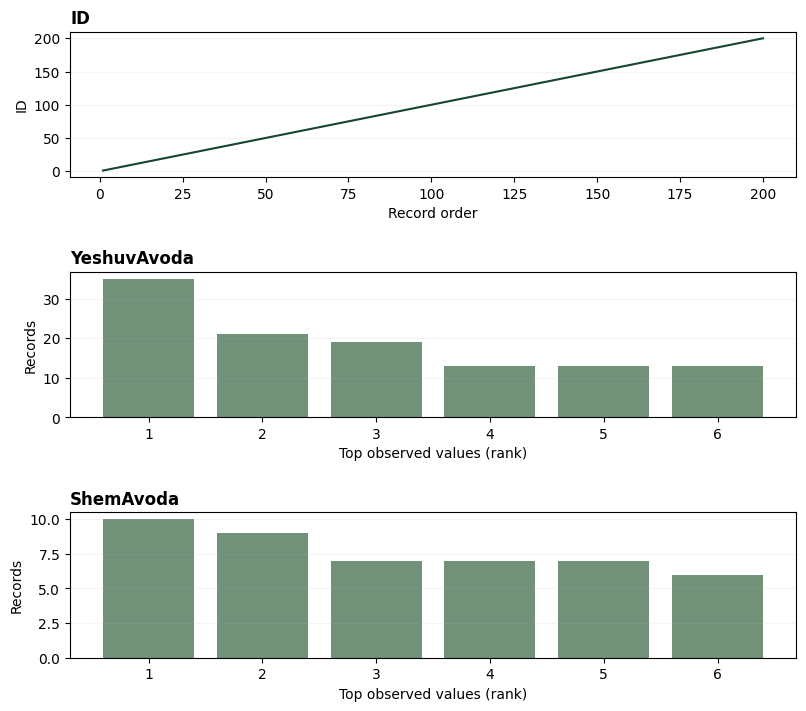

YeshuvAvoda: top observed source text: תל אביב (35) | ירושלים (21) | חיפה (19)
ShemAvoda: top observed source text: מסעדה (10) | משרד החינוך (9) | בנק לאומי (7)


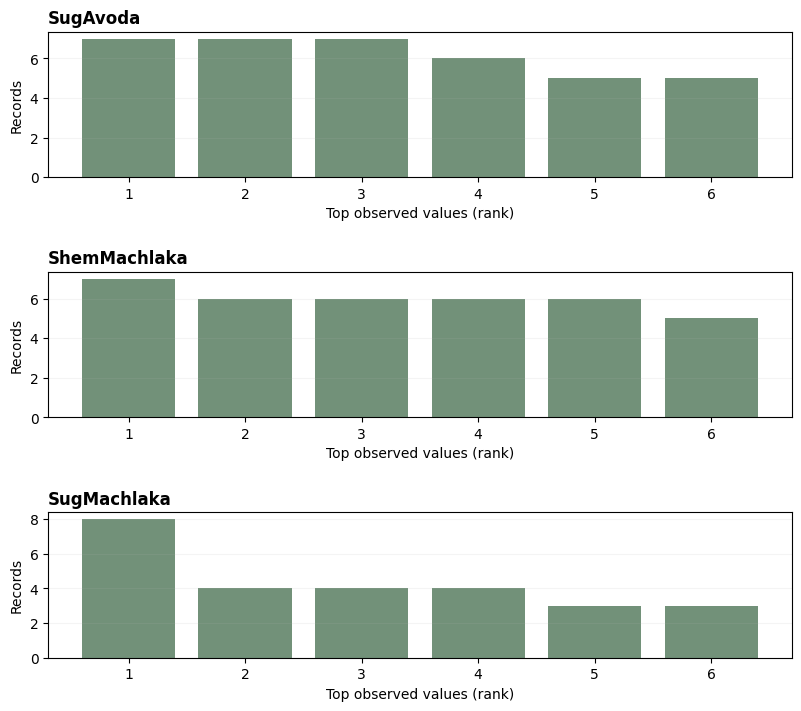

SugAvoda: top observed source text: בית ספר יסודי (7) | מסעדה (7) | חנות למכירת בגדים (7)
ShemMachlaka: top observed source text: שמירה (7) | תמיכה בלקוחות (6) | קוסמטיקה וטיפוח (6)
SugMachlaka: top observed source text: כנ"ל (8) | טיפול בחולי סרטן (4) | טיפול באנשים עם בעיות (4)


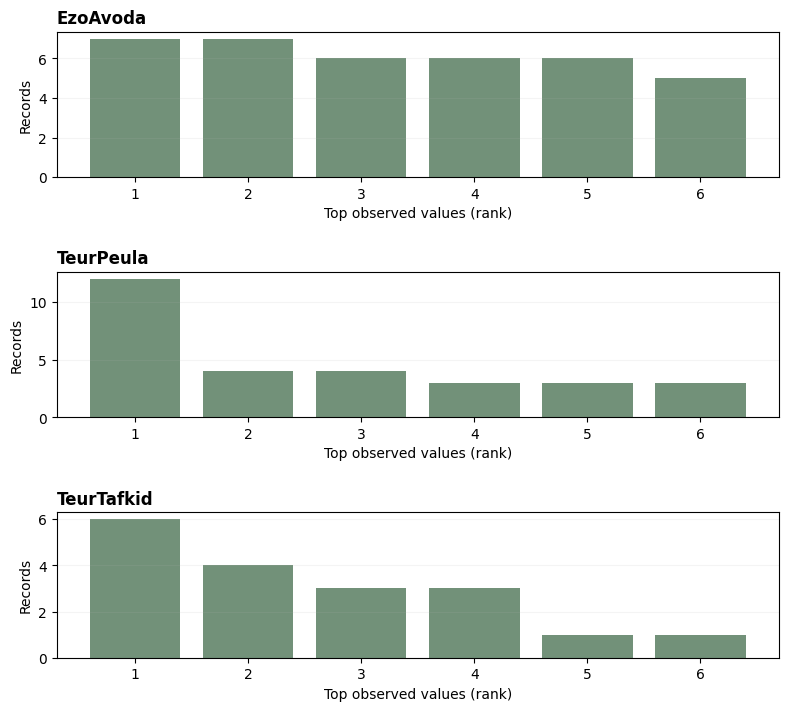

EzoAvoda: top observed source text: שומר בבית הספר (7) | טבח (7) | מנקה בית ספר אחרי הלימודים (6)
TeurPeula: top observed source text: כנ"ל (12) | מפקח על תהליך ייצור צ'יפים (4) | מסבירה לאנשים לגבי מוצרים של חברת LOREAL (4)
TeurTafkid: top observed source text: כלכלן (6) | כנ"ל (4) | סגן מנהל אגף (3)


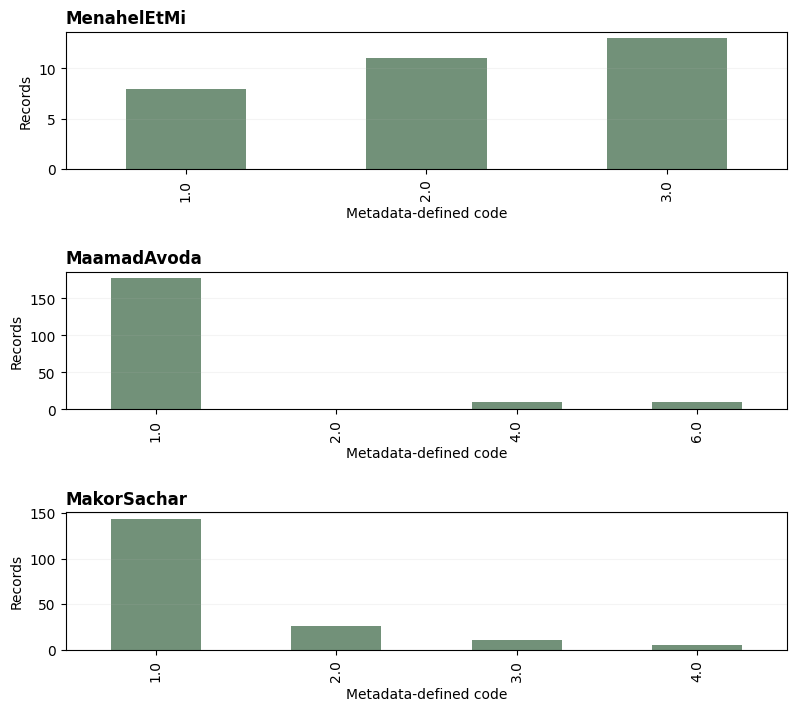

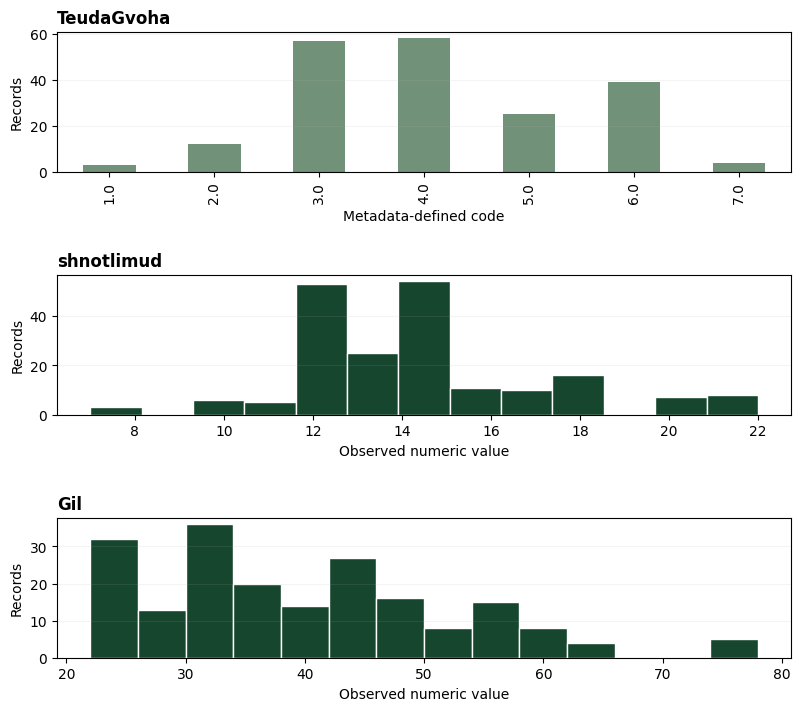

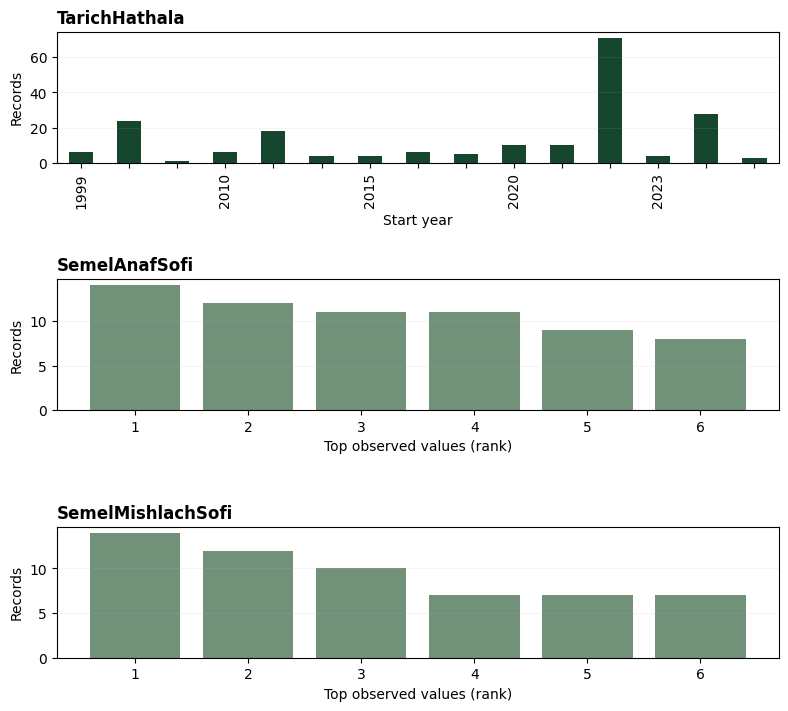

SemelAnafSofi: top observed source text: 5610 (14) | 6201 (12) | 8411 (11)
SemelMishlachSofi: top observed source text: 5223 (14) | 9112 (12) | 2512 (10)


In [7]:
def plot_from_type(field,ax):
    kind=contracts.loc[field,"פורמט"]
    s=survey[field]
    if kind=="DATE":
        yearly=pd.to_datetime(s,errors="coerce",format="mixed").dt.year.value_counts().sort_index()
        yearly.plot.bar(ax=ax,color=PALETTE["blue"])
        ax.set(xlabel="Start year",ylabel="Records")
        for n,item in enumerate(ax.get_xticklabels()):
            if n%3: item.set_visible(False)
    elif kind=="INTEGER" and enumerations[field]:
        counts=pd.to_numeric(s,errors="coerce").value_counts().sort_index()
        counts.plot.bar(ax=ax,color=PALETTE["teal"])
        ax.set(xlabel="Metadata-defined code",ylabel="Records")
    elif kind=="INTEGER" and field!="ID":
        nums=pd.to_numeric(s,errors="coerce").dropna()
        ax.hist(nums,bins=min(14,max(2,nums.nunique())),color=PALETTE["blue"],edgecolor="white")
        ax.set(xlabel="Observed numeric value",ylabel="Records")
    elif field=="ID":
        ax.plot(range(1,len(s)+1),pd.to_numeric(s),color=PALETTE["blue"])
        ax.set(xlabel="Record order",ylabel="ID")
    else:
        cleaned=s.astype("string").str.strip().replace("",pd.NA)
        counts=cleaned.value_counts().head(6)
        ax.bar(range(1,len(counts)+1),counts.values,color=PALETTE["teal"])
        ax.set_xticks(range(1,len(counts)+1))
        ax.set(xlabel="Top observed values (rank)",ylabel="Records")
    ax.set_title(field,loc="left",fontweight="bold",fontsize=12)
    ax.grid(axis="y",alpha=.13)

for start in range(0,len(survey.columns),3):
    fields=list(survey.columns[start:start+3])
    fig,axes=plt.subplots(len(fields),1,figsize=(8.4,7.5))
    for field,ax in zip(fields,np.atleast_1d(axes)):
        plot_from_type(field,ax)
    fig.tight_layout(pad=2.1)
    plt.show()
    for field in fields:
        if contracts.loc[field,"פורמט"]=="TEXT" and field!="ID":
            s=survey[field].astype("string").str.strip().replace("",pd.NA)
            observed=s.value_counts().head(3)
            print(f"{field}: top observed source text:",
                  " | ".join(f"{str(value)[:65]} ({count})" for value,count in observed.items()))

## 8. הפעלת כללים המצריכים משמעות של שדות: בנפרד מבדיקות טיפוס
בדיקות טיפוס לבדן אינן יכולות לקבוע אם שדה רלוונטי רק למעמד תעסוקה מסוים. בגיליון `Metadata` נכתב במפורש כי `MakorSachar` מלא רק עבור שכיר או חבר קואופרטיב, כפי שמוגדר ב-`MaamadAvoda`. הקודים המותרים נגזרים מהטקסט של **הערכים הממוספרים במקור**, ולא ממספרים שהוגדרו מראש בקוד.

הטענה "מלא רק כאשר ..." היא **תנאי הכרחי**, לא הוראה למלא תמיד כאשר התנאי מתקיים. לכן חוסר בשדה אצל שכיר אינו מסווג אוטומטית כהפרת חוזה. קוד סופי הכולל `X` מוגדר לפי מסמך המטלה כקוד חלקי, ולא מניחים שאפשר לשחזר אותו אוטומטית.

Applicable statuses (read from Metadata labels): {1, 5}
Salary-source conflicts: 9
Salary source with unknown status: 0
IDs of rule conflicts: [34, 49, 112, 140, 166, 176, 187, 190, 198]
Four-character target labels: 191 | target labels containing X: 9
Industry code-shape mismatches: 5
Industry X partial codes: 9


,field,rule,records
0,MakorSachar,salary_status_applicability,9
1,SemelAnafSofi,code_shape_mismatch,5


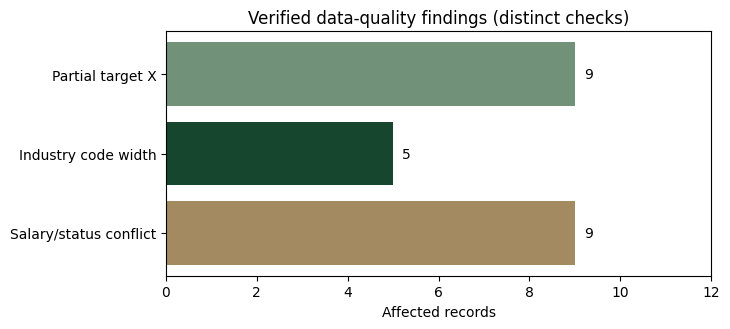

In [8]:
salary_field = metadata.loc[
    metadata["הסבר"].fillna("").str.contains("רק במידה",regex=False),"משתנה"
].tolist()
assert salary_field == ["MakorSachar"]
assert "MaamadAvoda" in str(contracts.loc["MakorSachar","הסבר"])
status_codes = enumerations["MaamadAvoda"]
salary_applicable_codes = {number for number,meaning in status_codes.items()
                           if "שכיר" in meaning or "חבר קואופרטיב" in meaning}
assert salary_applicable_codes == {1,5}, "Check the source's employment-status semantics"
status = pd.to_numeric(survey["MaamadAvoda"],errors="coerce")
salary_present = occupied(survey["MakorSachar"])
not_applicable = status.notna() & ~status.isin(salary_applicable_codes)
invalid_salary_context = not_applicable & salary_present
unknown_salary_context = status.isna() & salary_present
print("Applicable statuses (read from Metadata labels):",salary_applicable_codes)
print("Salary-source conflicts:",int(invalid_salary_context.sum()))
print("Salary source with unknown status:",int(unknown_salary_context.sum()))
print("IDs of rule conflicts:",survey.loc[invalid_salary_context,"ID"].astype(int).tolist())
assert invalid_salary_context.sum()==9
assert not unknown_salary_context.any()

industry_flags=validate_type(survey,"SemelAnafSofi")
target_flags=validate_type(survey,TARGET)
complete_mask = occupied(survey[TARGET]) & ~target_flags["partial_X_code"] & ~target_flags["code_shape_mismatch"]
partial_mask = target_flags["partial_X_code"]
assert int(complete_mask.sum())==191 and int(partial_mask.sum())==9
print("Four-character target labels:",int(complete_mask.sum()),
      "| target labels containing X:",int(partial_mask.sum()))
print("Industry code-shape mismatches:",int(industry_flags["code_shape_mismatch"].sum()))
print("Industry X partial codes:",int(industry_flags["partial_X_code"].sum()))

cross_issues=pd.DataFrame({"ID":survey.loc[invalid_salary_context,"ID"].astype(int),
                           "field":"MakorSachar","rule":"salary_status_applicability",
                           "source":"Metadata description and MaamadAvoda enumerated labels"})
issue_totals=(pd.concat([issues[["ID","field","rule"]],cross_issues[["ID","field","rule"]]],
                       ignore_index=True)
                .groupby(["field","rule"]).size().rename("records").reset_index())
display(issue_totals)

fig,ax=plt.subplots(figsize=(7.4,3.4))
keys=["Partial target X","Industry code width","Salary/status conflict"]
vals=[int(partial_mask.sum()),int(industry_flags["code_shape_mismatch"].sum()),int(invalid_salary_context.sum())]
ax.barh(keys[::-1],vals[::-1],color=[PALETTE["orange"],PALETTE["blue"],PALETTE["teal"]])
ax.set(xlabel="Affected records",title="Verified data-quality findings (distinct checks)")
for i,value in enumerate(vals[::-1]):ax.text(value+.2,i,str(value),va="center")
ax.set_xlim(0,max(vals)+3)
fig.tight_layout();plt.show()

## 9. כפילויות ותוויות סותרות
המסמך מתאר שידורים חוזרים. אולם `ID` הוא "מספר רץ" לפי Metadata ואינו מזהה משתתף יציב, ואין תאריך שידור. לפיכך אי אפשר להסיק שמספר שורות שייכות לאותו אדם. כתחליף מוגבל נבנית חתימה של שבעה שדות תיאור, המשמשת רק לבדיקת דמיון ולחלוקת אימון/בדיקה מופרדת קבוצות. כל שינוי בתיאורי הסקר עלול ליצור קבוצה חדשה גם אם מדובר באותו משתתף.

In [9]:
assert pd.to_numeric(survey["ID"],errors="coerce").is_unique
GROUP_FIELDS=["ShemAvoda","SugAvoda","ShemMachlaka","SugMachlaka",
              "EzoAvoda","TeurPeula","TeurTafkid"]
def normal_signature(x):
    if pd.isna(x): return ""
    return " ".join(re.sub(r"[^\w\u0590-\u05ff]+"," ",str(x).lower()).split())
groups=survey[GROUP_FIELDS].apply(
    lambda row:"|".join(normal_signature(row[k]) for k in GROUP_FIELDS),axis=1)
clusters=(survey.assign(group_signature=groups)
          .groupby("group_signature",dropna=False)
          .agg(records=("ID","size"),distinct_target_labels=(TARGET,"nunique")))
print("Description groups:",len(clusters),
      "| groups repeated:",int(clusters.records.gt(1).sum()),
      "| conflicting-label groups:",int(clusters.distinct_target_labels.gt(1).sum()))
conflict_keys=set(clusters.index[clusters.distinct_target_labels.gt(1)])
display(survey.loc[groups.isin(conflict_keys),["ID","ShemAvoda","EzoAvoda",TARGET]])

Description groups: 137 | groups repeated: 40 | conflicting-label groups: 1


,ID,ShemAvoda,EzoAvoda,SemelMishlachSofi
1,2.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3311
32,33.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
64,65.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
95,96.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211


## 10. בחירת תכונות לפי משמעותן וזמינותן
טיפוס הנתונים קובע את הבדיקות הראשוניות, אך אינו קובע לבדו אם שדה צריך להיכלל במודל. `INTEGER` בעל ערכים מקודדים יכול לייצג קטגוריות ולא משתנה רציף. גם זמינות השדה בזמן קבלת ההחלטה משפיעה על בחירת התכונות.

ההשוואה מבוססת על שישה שדות המתארים את העבודה, ארבעה שדות קטגוריאליים ושנות לימוד. `ID` משמש לזיהוי רשומה בלבד. שם המעסיק והיישוב נשמרים לבקרה ולקיבוץ תיאורים אך אינם קלט למודל. גיל ותאריך תחילת תפקיד נבדקים בניתוח הנתונים ומוחרגים מהמודל. `SemelAnafSofi` מוחרג משום שלא הוכח שהסמל הענפי הסופי זמין לפני סיווג משלח היד. `SemelMishlachSofi` הוא משתנה המטרה ולעולם אינו משמש כתכונת קלט.

אלו החלטות מידול מתועדות. הן אינן מוצגות כאילו נכתבו בגיליון `Metadata`.

In [10]:
APPROVED_TEXT=["SugAvoda","ShemMachlaka","SugMachlaka",
               "EzoAvoda","TeurPeula","TeurTafkid"]
APPROVED_CATEGORICAL=["MenahelEtMi","MaamadAvoda","MakorSachar","TeudaGvoha"]
APPROVED_NUMERIC=["shnotlimud"]
FEATURES=APPROVED_TEXT+APPROVED_CATEGORICAL+APPROVED_NUMERIC
EXCLUDED=[name for name in survey.columns if name not in FEATURES]
assert len(FEATURES)==11 and len(EXCLUDED)==7
assert all(contracts.loc[name,"פורמט"]=="TEXT" and not widths[name] for name in APPROVED_TEXT)
assert all(contracts.loc[name,"פורמט"]=="INTEGER" and bool(enumerations[name])
           for name in APPROVED_CATEGORICAL)
assert all(contracts.loc[name,"פורמט"]=="INTEGER" and not enumerations[name]
           for name in APPROVED_NUMERIC)
assert TARGET in EXCLUDED and "SemelAnafSofi" in EXCLUDED

for name in survey.columns:
    role=("TEXT_SIX_REPRESENTATIONS" if name in APPROVED_TEXT else
          "NOMINAL_ONE_HOT" if name in APPROVED_CATEGORICAL else
          "NUMERIC_IMPUTE_SCALE" if name in APPROVED_NUMERIC else
          "TARGET_NOT_FEATURE" if name==TARGET else
          "AUDIT_AND_GROUP_ONLY" if name=="ShemAvoda" else
          "AUDIT_EXCLUDED")
    r=summary.loc[summary.field.eq(name)].iloc[0]
    print(f"{name:20} Metadata={r['type']:7} Role={role:22} "
          f"Missing={r['missing']:3} Type issues={r['violations']:2}")

ID                   Metadata=INTEGER Role=AUDIT_EXCLUDED         Missing=  0 Type issues= 0
YeshuvAvoda          Metadata=TEXT    Role=AUDIT_EXCLUDED         Missing=  0 Type issues= 0
ShemAvoda            Metadata=TEXT    Role=AUDIT_AND_GROUP_ONLY   Missing=  0 Type issues= 0
SugAvoda             Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing= 25 Type issues= 0
ShemMachlaka         Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing= 64 Type issues= 0
SugMachlaka          Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing=134 Type issues= 0
EzoAvoda             Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing=  7 Type issues= 0
TeurPeula            Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing=136 Type issues= 0
TeurTafkid           Metadata=TEXT    Role=TEXT_SIX_REPRESENTATIONS Missing=172 Type issues= 0
MenahelEtMi          Metadata=INTEGER Role=NOMINAL_ONE_HOT        Missing=168 Type issues= 0
MaamadAvoda          Metadata=INTEGER Role=NOMINAL_ONE_HOT

## 11. ייצוג הטקסט ובחינת שמונה חלופות על אותו מסווג

ההשוואה שומרת על אותו מסווג ועל אותן חלוקות נתונים. שש עמודות טקסט מיוצגות בכל חלופה באופן שונה, ושאר התכונות אינן משתנות.

- **One-Hot:** קידוד נומינלי של כל ערך טקסט מלא.
- **TF-IDF:** ייצוג תווי מנורמל L2.
- **מרחקים אוקלידיים:** מרחק מתיאור האימון לעוגני אימון ייחודיים עם החלקת IDF ובלעדיה.
- **KMeans צפוף:** TF-IDF מנורמל L2 כמטריצת NumPy, עם החלקת IDF ובלעדיה.
- **MiniBatchKMeans דליל:** אותם ערכי TF-IDF מנורמלים L2 כמטריצת CSR, עם החלקת IDF ובלעדיה.

ארבע תצורות האשכולות משתמשות בשני מימושים של משפחת KMeans. מטריצה צפופה מאומנת באמצעות KMeans רגיל. מטריצת CSR מאומנת באמצעות MiniBatchKMeans. האשכולות מקודדים לאחר מכן באמצעות OneHotEncoder, ולא במספרים בעלי סדר. בחירת K מתבצעת בנתוני האימון בלבד באמצעות Calinski-Harabasz, תוך בדיקה של כל מספר אשכולות תקף מ-2 ועד המינימום של 1000 ומספר ערכי הטקסט הייחודיים פחות אחד. אין שימוש ב-KNN.

נציג את המטריצות האמיתיות שהוחזרו מ-TfidfVectorizer, את נורמות השורות, את ציוני K ואת עקומות ארבע התצורות בכל שדה. ההבדלים בין מטריצה צפופה לדלילה הם ייצוג אחסון ומסלול חישוב, ולא שתי שיטות למדידת דמיון. אין להסיק מן המדד לבדו משמעות מקצועית של אשכולות.

In [11]:
# Consistent field-level preprocessing for every candidate.
NO_SIGNAL_TEXT={'כנ"ל','כנ״ל','חסוי','לא יכול לפרט','0'}

def model_features(frame):
    df=pd.DataFrame(index=frame.index)
    for f in APPROVED_TEXT:
        val=(frame[f].astype('string').fillna('')
             .str.replace(r'\s+',' ',regex=True).str.strip())
        df[f]=val.mask(val.isin(NO_SIGNAL_TEXT),'').astype(str)
    for f in APPROVED_CATEGORICAL:
        val=pd.to_numeric(frame[f],errors='coerce').astype('Int64')
        df[f]=val.astype('string').fillna('MISSING').astype(str)
    status=pd.to_numeric(frame['MaamadAvoda'],errors='coerce')
    eligible=status.isin(salary_applicable_codes)
    unknown=status.isna()
    df.loc[~eligible & ~unknown,'MakorSachar']='NOT_APPLICABLE'
    df.loc[unknown,'MakorSachar']='APPLICABILITY_UNKNOWN'
    for f in APPROVED_NUMERIC:
        df[f]=pd.to_numeric(frame[f],errors='coerce')
    assert df[FEATURES].columns.tolist()==FEATURES
    return df[FEATURES]

complete_mask=~partial_mask
complete=survey.loc[complete_mask].copy()
partial=survey.loc[partial_mask].copy()
X=model_features(complete)
y=complete[TARGET].astype(str)
group_ids=groups.loc[complete.index]
assert len(complete)==191 and len(partial)==9
splitter=GroupShuffleSplit(n_splits=1,test_size=.22,random_state=SEED)
train_idx,test_idx=next(splitter.split(X,y,groups=group_ids))
X_train,X_test=X.iloc[train_idx],X.iloc[test_idx]
y_train,y_test=y.iloc[train_idx],y.iloc[test_idx]
g_train=group_ids.iloc[train_idx]
assert set(g_train).isdisjoint(set(group_ids.iloc[test_idx]))
assert TARGET not in X.columns and 'SemelAnafSofi' not in X.columns
print('Training records:',len(X_train),'| Frozen external holdout:',len(X_test))
print('Target classes in training:',y_train.nunique(), '| Holdout labels never seen in training:',(~y_test.isin(set(y_train))).sum())

Training records: 149 | Frozen external holdout: 42
Target classes in training: 52 | Holdout labels never seen in training: 8


## 12. מטריצת TF-IDF ובחירת מספר האשכולות

לכל שדה טקסט בונים מטריצת TF-IDF מתוך ערכי האימון הייחודיים בלבד. נבחנות שתי אפשרויות של `smooth_idf`. בשתיהן מופעל נרמול `norm="l2"` לפני התאמת KMeans. השוואת קלט צפוף לקלט CSR מבוססת על אותם ערכים מספריים.

כל שיטה בודקת בסדר עולה את כל הערכים השלמים של `K` החל מ-2 ועד `min(1000, unique_text_count - 1)` עבור אותו שדה. כל ארבע התצורות מקבלות טווח זהה. בתחילת כל חיפוש `optimal_cluster_count = 0` וערך `maximum_calinski_harabasz_score = 0`. הציון המיטבי ומספר האשכולות מתעדכנים רק אם מתקבל ציון תקף שגדול ממש מן המקסימום הקודם. תיקו מדויק משאיר את ערך K הנמוך יותר.

המרחק האוקלידי בין שני וקטורים בעלי נורמת L2 השווה ל-1 מקיים `distance_squared = 2 * (1 - cosine_similarity)`. KMeans מקטין את סכום המרחקים האוקלידיים בריבוע למרכזי האשכולות. Calinski-Harabasz מודד יחס פיזור בין האשכולות לפיזור בתוכם, תוך התחשבות במספר האשכולות ובמספר התיאורים. מרכזי KMeans עצמם אינם חייבים להיות וקטורי יחידה.

המדד אינו מוודא התאמה סמנטית או נכונות מקצועית. בחירה במספר אשכולות גבוה מאוד עלולה להצביע על קיבוץ מצומצם בפועל, גם כשהציון מרבי. לכן מוצגים גם ציוני כל K וגם שיוכי תיאורים ממשיים לבדיקה מקצועית.

In [12]:
TFIDF_OPTIONS={'analyzer':'char','ngram_range':(2,4),'norm':'l2',
               'sublinear_tf':True,'max_features':1200}
MAX_K=1000
MAX_K_HARD=1000
KMEANS_N_INIT=3
KMEANS_MAX_ITER=130


def tfidf(smooth):
    return TfidfVectorizer(**TFIDF_OPTIONS,smooth_idf=bool(smooth))


def as_text_array(X):
    if isinstance(X,pd.Series):
        return X.fillna('').astype(str).tolist()
    if isinstance(X,pd.DataFrame):
        return X.iloc[:,0].fillna('').astype(str).tolist()
    arr=np.asarray(X,dtype=object)
    return pd.Series(arr.ravel()).fillna('').astype(str).tolist()


class EuclideanToTrainingText(BaseEstimator,TransformerMixin):
    """Distances to every distinct training-only TF-IDF reference text."""
    def __init__(self,smooth_idf=True,max_features=1200):
        self.smooth_idf=smooth_idf;self.max_features=max_features

    def fit(self,X,y=None):
        values=as_text_array(X)
        self.references_=sorted(set(values))
        self.encoder_=TfidfVectorizer(analyzer='char',ngram_range=(2,4),norm='l2',
                                     max_features=self.max_features,
                                     sublinear_tf=True,smooth_idf=self.smooth_idf)
        # A field entirely missing in a fold must remain valid.
        if not any(v.strip() for v in values):
            self.all_missing_=True
            return self
        self.all_missing_=False
        self.encoder_.fit(values)
        self.anchor_vectors_=self.encoder_.transform(self.references_)
        return self

    def transform(self,X):
        vals=as_text_array(X)
        if self.all_missing_:
            return np.zeros((len(vals),1))
        mat=self.encoder_.transform(vals)
        distances=euclidean_distances(mat,self.anchor_vectors_)
        assert distances.shape==(len(vals),len(self.references_))
        return distances


class CalinskiHarabaszTextClusterer(BaseEstimator, TransformerMixin):
    """KMeans on dense vectors or MiniBatchKMeans on sparse CSR vectors."""
    def __init__(self, fields, smooth_idf=True, representation='dense',
                 max_k=1000, max_features=900, n_init=KMEANS_N_INIT,
                 max_iter=KMEANS_MAX_ITER, random_state=SEED):
        self.fields=fields
        self.smooth_idf=smooth_idf
        self.representation=representation
        self.max_k=max_k
        self.max_features=max_features
        self.n_init=n_init
        self.max_iter=max_iter
        self.random_state=random_state

    def fit(self, X, y=None):
        if self.representation not in ('dense', 'sparse'):
            raise ValueError('representation must be dense or sparse')

        input_frame = pd.DataFrame(X, columns=self.fields)
        self.models_ = {}
        self.scores_ = []
        self.selection_ = []
        self.matrix_checks_ = []

        for field_name in self.fields:
            distinct_text_values = sorted(
                value for value in input_frame[field_name].fillna('').astype(str).unique()
                if value.strip()
            )
            field_model_state = {
                'kind': 'fallback', 'lookup': {}, 'chosen_k': None,
                'field': field_name, 'distinct_texts': len(distinct_text_values)
            }

            if len(distinct_text_values) >= 3:
                vectorizer = TfidfVectorizer(
                    analyzer='char', ngram_range=(2, 4), norm='l2',
                    max_features=self.max_features, sublinear_tf=True,
                    smooth_idf=self.smooth_idf
                )
                normalized_sparse_vectors = vectorizer.fit_transform(distinct_text_values).tocsr()
                normalized_dense_vectors = normalized_sparse_vectors.toarray()
                row_l2_norms = np.linalg.norm(normalized_dense_vectors, axis=1)
                assert np.allclose(row_l2_norms, 1.0, atol=1e-9, rtol=1e-9), field_name
                assert np.array_equal(normalized_sparse_vectors.toarray(), normalized_dense_vectors)

                distinct_vector_count = int(np.unique(
                    np.round(normalized_dense_vectors, 12), axis=0
                ).shape[0])
                maximum_candidate_cluster_count = min(
                    1000, self.max_k, len(distinct_text_values) - 1
                )
                self.matrix_checks_.append({
                    'field': field_name,
                    'smooth_idf': self.smooth_idf,
                    'matrix': self.representation,
                    'shape': tuple(normalized_dense_vectors.shape),
                    'nnz': int(normalized_sparse_vectors.nnz),
                    'min_L2': float(row_l2_norms.min()),
                    'max_L2': float(row_l2_norms.max()),
                    'max_k': maximum_candidate_cluster_count,
                    'is_csr': bool(issparse(normalized_sparse_vectors)),
                    'unique_vectors': distinct_vector_count,
                    'unique_text_values': len(distinct_text_values)
                })

                if maximum_candidate_cluster_count >= 2:
                    clustering_input = (
                        normalized_sparse_vectors if self.representation == 'sparse'
                        else normalized_dense_vectors
                    )
                    assert bool(issparse(clustering_input)) == (self.representation == 'sparse')

                    optimal_cluster_count = 0
                    maximum_calinski_harabasz_score = 0.0
                    optimal_cluster_estimator = None

                    # Every candidate K is evaluated in ascending integer order.
                    # A strict improvement retains the earliest, smaller K on exact ties.
                    for candidate_cluster_count in range(2, maximum_candidate_cluster_count + 1):
                        if self.representation == 'dense':
                            candidate_cluster_estimator = KMeans(
                                n_clusters=candidate_cluster_count,
                                n_init=self.n_init, max_iter=self.max_iter,
                                random_state=self.random_state, algorithm='lloyd'
                            )
                        else:
                            candidate_cluster_estimator = MiniBatchKMeans(
                                n_clusters=candidate_cluster_count,
                                n_init=self.n_init, max_iter=self.max_iter,
                                random_state=self.random_state,
                                batch_size=max(256, len(distinct_text_values)),
                                reassignment_ratio=0.0, compute_labels=True
                            )

                        cluster_assignments = candidate_cluster_estimator.fit_predict(clustering_input)
                        observed_cluster_count = int(np.unique(cluster_assignments).size)
                        candidate_is_valid = (
                            observed_cluster_count == candidate_cluster_count
                            and 2 <= observed_cluster_count < len(distinct_text_values)
                        )
                        # scikit-learn's CH implementation requires dense input, but
                        # the exact same L2-normalized values are used for both branches.
                        candidate_calinski_harabasz_score = (
                            float(calinski_harabasz_score(
                                normalized_dense_vectors, cluster_assignments
                            )) if candidate_is_valid else float('nan')
                        )
                        self.scores_.append({
                            'field': field_name,
                            'smoothing': self.smooth_idf,
                            'input': self.representation,
                            'k': candidate_cluster_count,
                            'ch': candidate_calinski_harabasz_score,
                            'valid': bool(np.isfinite(candidate_calinski_harabasz_score)),
                            'observed_clusters': observed_cluster_count,
                            'algorithm': type(candidate_cluster_estimator).__name__
                        })

                        if (
                            np.isfinite(candidate_calinski_harabasz_score)
                            and candidate_calinski_harabasz_score > maximum_calinski_harabasz_score
                        ):
                            maximum_calinski_harabasz_score = candidate_calinski_harabasz_score
                            optimal_cluster_count = candidate_cluster_count
                            optimal_cluster_estimator = candidate_cluster_estimator

                    if optimal_cluster_estimator is not None:
                        field_model_state.update({
                            'kind': 'kmeans',
                            'vectorizer': vectorizer,
                            'kmeans': optimal_cluster_estimator,
                            'chosen_k': optimal_cluster_count,
                            'ch': maximum_calinski_harabasz_score,
                            'lookup': {
                                value: f'cluster_{int(assignment):03d}'
                                for value, assignment in zip(
                                    distinct_text_values, optimal_cluster_estimator.labels_
                                )
                            }
                        })

                        # Independent calculation of the variance ratio verifies
                        # the score returned by scikit-learn for the selected K.
                        cluster_centroids = np.vstack([
                            normalized_dense_vectors[
                                optimal_cluster_estimator.labels_ == cluster_index
                            ].mean(axis=0)
                            for cluster_index in range(optimal_cluster_count)
                        ])
                        global_mean = normalized_dense_vectors.mean(axis=0)
                        cluster_sample_counts = np.bincount(
                            optimal_cluster_estimator.labels_,
                            minlength=optimal_cluster_count
                        )
                        between_cluster_dispersion = float((
                            cluster_sample_counts[:, None]
                            * (cluster_centroids - global_mean) ** 2
                        ).sum())
                        within_cluster_dispersion = float((
                            (normalized_dense_vectors
                             - cluster_centroids[optimal_cluster_estimator.labels_]) ** 2
                        ).sum())
                        independently_calculated_score = (
                            (between_cluster_dispersion / (optimal_cluster_count - 1))
                            / (within_cluster_dispersion
                               / (len(distinct_text_values) - optimal_cluster_count))
                        )
                        assert np.isclose(
                            independently_calculated_score,
                            maximum_calinski_harabasz_score,
                            rtol=1e-7, atol=1e-7
                        )
                        field_model_state['manual_ch'] = independently_calculated_score

            if field_model_state['kind'] == 'fallback':
                field_model_state['lookup'] = {
                    value: f'value_{index:03d}'
                    for index, value in enumerate(distinct_text_values)
                }

            self.models_[field_name] = field_model_state
            self.selection_.append({
                'field': field_name,
                'smoothing': self.smooth_idf,
                'input': self.representation,
                'algorithm': (
                    'KMeans' if self.representation == 'dense' else 'MiniBatchKMeans'
                ),
                'n_distinct_values': len(distinct_text_values),
                'chosen_k': field_model_state['chosen_k'],
                'ch_score': field_model_state.get('ch', np.nan),
                'manual_ch': field_model_state.get('manual_ch', np.nan),
                'status': field_model_state['kind']
            })

        self.score_table_ = pd.DataFrame(self.scores_, columns=[
            'field', 'smoothing', 'input', 'k', 'ch', 'valid',
            'observed_clusters', 'algorithm'
        ])
        self.selection_table_ = pd.DataFrame(self.selection_)
        self.matrix_checks_table_ = pd.DataFrame(self.matrix_checks_)
        return self

    def transform(self,X):
        if not hasattr(self,'models_'):
            raise ValueError('fit() must precede transform()')
        frame=pd.DataFrame(X,columns=self.fields)
        output=np.empty((len(frame),len(self.fields)),dtype=object)
        for j,field in enumerate(self.fields):
            entry=self.models_[field]
            values=frame[field].fillna('').astype(str).tolist()
            assignments=[]
            for value in values:
                if not value.strip():assignments.append('MISSING')
                elif value in entry['lookup']:assignments.append(entry['lookup'][value])
                elif entry['kind']=='kmeans':
                    vector=entry['vectorizer'].transform([value])
                    if self.representation=='dense':vector=vector.toarray()
                    label=int(entry['kmeans'].predict(vector)[0])
                    assignments.append(f'cluster_{label:03d}')
                else: assignments.append('UNSEEN_VALUE')
            output[:,j]=assignments
        return output

    def get_feature_names_out(self,input_features=None):
        return np.asarray(self.fields,dtype=object)

# Verify the literal nominal encoding: no integer ordering is ever supplied.
probe=pd.DataFrame({'field':['software','software','maintenance']})
encoder=EuclideanToTrainingText(smooth_idf=True).fit(probe[['field']])
assert encoder.transform(probe[['field']]).shape[1]==2
print('Distance prototypes are derived from training values only.')

Distance prototypes are derived from training values only.


## 13. מטריצות המספרים האמיתיות לפני הקיבוץ

לכל שדה טקסט מוצגים ערכי מטריצת TF-IDF שחושבו בפועל, פעם עם החלקת IDF ופעם בלעדיה. כותרות העמודות הן רצפי התווים שהחזיר הממיר, והשורות הן תיאורים מתוך קבוצת האימון. טבלת התצוגה מציגה חלק מן המטריצה כדי לאפשר קריאה, אך המטריצה המלאה נבדקת ומיוצאת לקובץ CSV לכל תצורה. שום ערך אינו מחושב לצורך המחשה בלבד.

כל שורה לא ריקה עוברת נרמול L2 לפני הפעלת KMeans. המרה בין CSR ל-NumPy שומרת על אותם ערכים מספריים. מבחני `assert` מאמתים את שני התנאים לכל שדה ולכל הגדרת החלקה.

In [13]:
# Inspect the exact TF-IDF output before any K-means fit.
MATRIX_AUDIT_DIR=Path(os.environ.get('CBS_OCCUPATION_OUTPUT_DIR',
                                     'occupation_classification_outputs'))/'tfidf_matrices'
MATRIX_AUDIT_DIR.mkdir(parents=True,exist_ok=True)
matrix_audit=[]
for field in APPROVED_TEXT:
    observed=sorted(v for v in X_train[field].fillna('').astype(str).unique() if v.strip())
    for smooth in (True,False):
        v=TfidfVectorizer(analyzer='char',ngram_range=(2,4),
                           norm='l2',smooth_idf=smooth,sublinear_tf=True,
                           max_features=900)
        actual_csr=v.fit_transform(observed).tocsr()
        actual_dense=actual_csr.toarray()
        norms=np.linalg.norm(actual_dense,axis=1)
        assert np.allclose(norms,np.ones(len(observed)),rtol=1e-9,atol=1e-9)
        assert np.array_equal(actual_csr.toarray(),actual_dense)
        terms=v.get_feature_names_out()
        raw_matrix=pd.DataFrame(actual_dense,index=pd.Index(observed,name='observed_text'),
                                columns=terms)
        safe=f'{field}_smooth_{int(smooth)}'
        raw_matrix.to_csv(MATRIX_AUDIT_DIR/f'{safe}.csv',encoding='utf-8-sig',float_format='%.16g')
        chosen=np.argsort(-actual_dense.max(axis=0),kind='stable')[:min(12,len(terms))]
        print(f'ACTUAL TF-IDF MATRIX | {field} | smooth_idf={smooth} | '
              f'shape={actual_dense.shape} | CSR nonzero={actual_csr.nnz}')
        print(f'L2 min={norms.min():.12f} max={norms.max():.12f} | '
              f'dense/CSR values identical: {np.array_equal(actual_dense,actual_csr.toarray())}')
        display(raw_matrix.iloc[:min(8,len(observed)),chosen].round(6))
        matrix_audit.append({'field':field,'smooth_idf':smooth,'observations':len(observed),
          'features':len(terms),'nonzeros':actual_csr.nnz,'min_l2':norms.min(),
          'max_l2':norms.max(),'complete_matrix_file':f'{safe}.csv'})
matrix_audit=pd.DataFrame(matrix_audit)
display(matrix_audit)
assert len(matrix_audit)==2*len(APPROVED_TEXT)

ACTUAL TF-IDF MATRIX | SugAvoda | smooth_idf=True | shape=(64, 900) | CSR nonzero=1570
L2 min=1.000000000000 max=1.000000000000 | dense/CSR values identical: True


,טב,טבח,חק,חקן,קן,וקח,קח,בח,וק,סופ,סופר,לצר
observed_text,,,,,,,,,,,,
"איסוף, עיבוד ופרסום נתונים",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אירוח,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אפיית לחם,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אריזה,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אתר בניה אצל קבלן,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אתר בנייה,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
בית ספר יסודי,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
גן ילדים,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


ACTUAL TF-IDF MATRIX | SugAvoda | smooth_idf=False | shape=(64, 900) | CSR nonzero=1570
L2 min=1.000000000000 max=1.000000000000 | dense/CSR values identical: True


,טב,טבח,חק,חקן,קן,וקח,קח,בח,סופ,סופר,וק,לצר
observed_text,,,,,,,,,,,,
"איסוף, עיבוד ופרסום נתונים",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אירוח,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אפיית לחם,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אריזה,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אתר בניה אצל קבלן,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אתר בנייה,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
בית ספר יסודי,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
גן ילדים,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


ACTUAL TF-IDF MATRIX | ShemMachlaka | smooth_idf=True | shape=(50, 618) | CSR nonzero=845
L2 min=1.000000000000 max=1.000000000000 | dense/CSR values identical: True


,"""א",&d,r&,r&d,"כ""","כ""א",מש,משק,שק,לי,מנ,מנה
observed_text,,,,,,,,,,,,
DELIVERY,0.0,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
R&D,0.0,0.57735,0.57735,0.57735,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אריזה,0.0,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
אשראי,0.0,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ביולוגיה,0.0,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
הנדסה,0.0,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
הנדסת תוכנה,0.0,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
הנהלת חשבונות,0.0,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


... (15 outputs left out)

,כל,וקר,סו,סוק,סוקר,קר,יד,פק,פקי,פקיד,קי,קיד
observed_text,,,,,,,,,,,,
בונה מודלים של AI,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
טכנאי מחשבים,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
כלכלן,0.539024,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
מנהל פיתןח של 2 מוצרים,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
מנהלת משאבי אנוש,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
סגן מנהל אגף,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
סוקר,0.000000,0.418024,0.418024,0.418024,0.418024,0.418024,0.0,0.0,0.0,0.0,0.0,0.0
"סמנכ""ל שיווק",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0


ACTUAL TF-IDF MATRIX | TeurTafkid | smooth_idf=False | shape=(10, 237) | CSR nonzero=280
L2 min=1.000000000000 max=1.000000000000 | dense/CSR values identical: True


,כל,וקר,סו,סוק,סוקר,קר,יד,פק,פקי,פקיד,קי,קיד
observed_text,,,,,,,,,,,,
בונה מודלים של AI,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
טכנאי מחשבים,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
כלכלן,0.539024,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
מנהל פיתןח של 2 מוצרים,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
מנהלת משאבי אנוש,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
סגן מנהל אגף,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
סוקר,0.000000,0.421664,0.421664,0.421664,0.421664,0.421664,0.0,0.0,0.0,0.0,0.0,0.0
"סמנכ""ל שיווק",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0


,field,smooth_idf,observations,features,nonzeros,min_l2,max_l2,complete_matrix_file
0,SugAvoda,True,64,900,1570,1.0,1.0,SugAvoda_smooth_1.csv
1,SugAvoda,False,64,900,1570,1.0,1.0,SugAvoda_smooth_0.csv
2,ShemMachlaka,True,50,618,845,1.0,1.0,ShemMachlaka_smooth_1.csv
3,ShemMachlaka,False,50,618,845,1.0,1.0,ShemMachlaka_smooth_0.csv
4,SugMachlaka,True,27,514,740,1.0,1.0,SugMachlaka_smooth_1.csv
5,SugMachlaka,False,27,514,740,1.0,1.0,SugMachlaka_smooth_0.csv
6,EzoAvoda,True,67,900,1932,1.0,1.0,EzoAvoda_smooth_1.csv
7,EzoAvoda,False,67,900,1932,1.0,1.0,EzoAvoda_smooth_0.csv
8,TeurPeula,True,24,900,1362,1.0,1.0,TeurPeula_smooth_1.csv
9,TeurPeula,False,24,900,1362,1.0,1.0,TeurPeula_smooth_0.csv


## 14. אימון אחיד והשוואה הוגנת

כל שמונה צינורות האימון נבנים באמצעות אותה פונקציה ונבדלים רק בייצוג הטקסט. ארבע תצורות KMeans נבדלות בבחירה בין KMeans רגיל על קלט צפוף לבין MiniBatchKMeans על קלט CSR דליל, ובהחלקת IDF. כל מאפיין הדורש התאמה נלמד מתוך קבוצת האימון בלבד.

כלל הבחירה נקבע מראש: דירוג השיטות לפי ממוצע Macro-F1 באימות קבוצתי פנימי, אחריו Macro-Recall, ואחריו פשטות. תוצאות קבוצת הבדיקה החיצונית מוצגות להשוואה ואינן משמשות לבחירה חוזרת.

In [14]:
VARIANTS=[
 ('onehot','One-hot: complete texts',None),
 ('tfidf','Direct TF-IDF smooth',True),
 ('euclidean','Euclidean TF-IDF smooth',True),
 ('euclidean','Euclidean TF-IDF no smooth',False),
 ('cluster_dense','CH dense KMeans smooth',True),
 ('cluster_dense','CH dense KMeans no smooth',False),
 ('cluster_sparse','CH sparse MiniBatchKMeans smooth',True),
 ('cluster_sparse','CH sparse MiniBatchKMeans no smooth',False),
]

def variant_name(kind,smooth):
    return next(name for k,name,s in VARIANTS if kind==k and smooth==s)


def build_candidate(kind,smooth=None):
    if kind=='onehot':
        text_transformers=[('text_labels',OneHotEncoder(handle_unknown='ignore'),
                            APPROVED_TEXT)]
    elif kind=='tfidf':
        text_transformers=[(f'text_{field}',tfidf(smooth),field)
                            for field in APPROVED_TEXT]
    elif kind=='euclidean':
        text_transformers=[(f'dist_{field}',EuclideanToTrainingText(
                              smooth_idf=smooth),field) for field in APPROVED_TEXT]
    elif kind in ('cluster_dense','cluster_sparse'):
        matrix_type='dense' if kind=='cluster_dense' else 'sparse'
        clustering=Pipeline([
            ('assign',CalinskiHarabaszTextClusterer(tuple(APPROVED_TEXT),
                    smooth_idf=smooth,representation=matrix_type)),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ])
        text_transformers=[('cluster_text',clustering,APPROVED_TEXT)]
    else:
        raise ValueError(f'Unknown representation: {kind}')
    preprocessing=ColumnTransformer([
        *text_transformers,
        ('nominal',OneHotEncoder(handle_unknown='ignore'),APPROVED_CATEGORICAL),
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),
                             ('scale',StandardScaler())]),APPROVED_NUMERIC)
    ],remainder='drop',sparse_threshold=1.0)
    return Pipeline([
        ('represent',preprocessing),
        ('classifier',LogisticRegression(C=1.,max_iter=1200,solver='lbfgs',
                                         random_state=SEED))
    ])

candidates={name:build_candidate(kind,smooth) for kind,name,smooth in VARIANTS}
assert len(candidates)==8
assert {type(m.named_steps['classifier']).__name__ for m in candidates.values()}=={'LogisticRegression'}
print('Comparable models:',len(candidates))
for name in candidates: print(name)

Comparable models: 8
One-hot: complete texts
Direct TF-IDF smooth
Euclidean TF-IDF smooth
Euclidean TF-IDF no smooth
CH dense KMeans smooth
CH dense KMeans no smooth
CH sparse MiniBatchKMeans smooth
CH sparse MiniBatchKMeans no smooth


## 15. השוואת שמונה השיטות על קבוצת בדיקה נפרדת

המסווג, תכונות הרקע, חלוקת הנתונים ומדדי ההערכה זהים בין כל השיטות. קבוצת הבדיקה מוערכת רק לאחר קביעת סדר העדיפות באמצעות אימות פנימי. המדדים מוצגים במלואם גם אם השיטה המורכבת יותר אינה משפרת את התוצאה.

In [15]:
def classification_metrics(y_true,y_pred):
    return {'accuracy':accuracy_score(y_true,y_pred),
            'macro_precision':precision_score(y_true,y_pred,average='macro',zero_division=0),
            'macro_recall':recall_score(y_true,y_pred,average='macro',zero_division=0),
            'macro_f1':f1_score(y_true,y_pred,average='macro',zero_division=0),
            'weighted_recall':recall_score(y_true,y_pred,average='weighted',zero_division=0),
            'weighted_f1':f1_score(y_true,y_pred,average='weighted',zero_division=0)}

inner=GroupShuffleSplit(n_splits=3,test_size=.24,random_state=SEED+10)
inner_splits=list(inner.split(X_train,y_train,groups=g_train))
inner_records=[]
for split_i,(a,b) in enumerate(inner_splits,start=1):
    assert set(g_train.iloc[a]).isdisjoint(set(g_train.iloc[b]))
    for kind,label,smoothing in VARIANTS:
        t0=perf_counter()
        candidate=build_candidate(kind,smoothing)
        candidate.fit(X_train.iloc[a],y_train.iloc[a])
        pred=candidate.predict(X_train.iloc[b])
        row={'split':split_i,'model':label,'family':kind,'smooth_idf':smoothing,
             'train_rows':len(a),'valid_rows':len(b),
             'unseen_label_rows':int((~y_train.iloc[b].isin(set(y_train.iloc[a]))).sum()),
             'fit_sec':perf_counter()-t0}
        row.update(classification_metrics(y_train.iloc[b],pred))
        inner_records.append(row)
inner_results=pd.DataFrame(inner_records)
inner_summary=(inner_results.groupby('model',as_index=False)
    .agg(macro_f1_mean=('macro_f1','mean'),macro_f1_sd=('macro_f1','std'),
         macro_recall_mean=('macro_recall','mean'),weighted_f1_mean=('weighted_f1','mean'),
         accuracy_mean=('accuracy','mean'),runtime_sec=('fit_sec','sum')))
# Primary metric was fixed before viewing the external holdout.
priority={name:i for i,(_,name,_) in enumerate(VARIANTS)}
inner_summary['complexity_order']=inner_summary.model.map(priority)
inner_summary=inner_summary.sort_values(['macro_f1_mean','macro_recall_mean','complexity_order'],
    ascending=[False,False,True]).reset_index(drop=True)
SELECTED=inner_summary.loc[0,'model']
print('Selected by internal validation:',SELECTED)
display(inner_summary.round(4))
print('Individual validation splits:')
display(inner_results[['split','model','valid_rows','unseen_label_rows',
                       'macro_f1','macro_recall','weighted_f1','accuracy']].round(3))

Selected by internal validation: Direct TF-IDF smooth


,model,macro_f1_mean,macro_f1_sd,macro_recall_mean,weighted_f1_mean,accuracy_mean,runtime_sec,complexity_order
0,Direct TF-IDF smooth,0.4801,0.0322,0.5001,0.6347,0.6410,5.5286,1
1,Euclidean TF-IDF smooth,0.4419,0.0548,0.4771,0.5846,0.6138,19.7545,2
2,Euclidean TF-IDF no smooth,0.4419,0.0548,0.4771,0.5846,0.6138,26.0965,3
3,CH dense KMeans smooth,0.4258,0.0107,0.4469,0.5891,0.6022,7.5340,4
4,CH dense KMeans no smooth,0.4210,0.0107,0.4417,0.5891,0.6022,8.9974,5
5,CH sparse MiniBatchKMeans smooth,0.4210,0.0107,0.4417,0.5891,0.6022,17.6038,6
6,CH sparse MiniBatchKMeans no smooth,0.4210,0.0107,0.4417,0.5891,0.6022,16.6644,7
7,One-hot: complete texts,0.3722,0.0169,0.3903,0.5363,0.5462,3.2021,0


Individual validation splits:


,split,model,valid_rows,unseen_label_rows,macro_f1,macro_recall,weighted_f1,accuracy
0,1,One-hot: complete texts,33,9,0.389,0.380,0.560,0.545
1,1,Direct TF-IDF smooth,33,9,0.472,0.458,0.626,0.606
2,1,Euclidean TF-IDF smooth,33,9,0.447,0.455,0.566,0.576
3,1,Euclidean TF-IDF no smooth,33,9,0.447,0.455,0.566,0.576
4,1,CH dense KMeans smooth,33,9,0.433,0.420,0.596,0.576
5,1,CH dense KMeans no smooth,33,9,0.433,0.420,0.596,0.576
6,1,CH sparse MiniBatchKMeans smooth,33,9,0.433,0.420,0.596,0.576
7,1,CH sparse MiniBatchKMeans no smooth,33,9,0.433,0.420,0.596,0.576
8,2,One-hot: complete texts,39,12,0.356,0.383,0.470,0.487
9,2,Direct TF-IDF smooth,39,12,0.452,0.500,0.550,0.590


## 16. השוואת שמונה השיטות על קבוצת הבדיקה

לאחר בחירת השיטה באימות פנימי מאמנים את כל שמונה החלופות מחדש על מלוא קבוצת האימון ומעריכים אותן על אותם 42 סקרים. המדדים מוצגים גם כאשר שיטה שאינה נבחרת מציגה ציון גבוה יותר במדד מסוים. תוצאות קבוצת הבדיקה אינן משמשות לשינוי הבחירה בדיעבד.

In [16]:
outer_models={};outer_predictions={};outer_rows=[]
for kind,name,smoothing in VARIANTS:
    candidate=build_candidate(kind,smoothing)
    start=perf_counter()
    candidate.fit(X_train,y_train)
    prediction=candidate.predict(X_test)
    represented=candidate.named_steps['represent'].transform(X_train)
    data={'model':name,'family':kind,'smooth_idf':smoothing,
          'n_features':represented.shape[1],'fit_sec':perf_counter()-start,
          'correct':int(np.sum(prediction==y_test.to_numpy()))}
    data.update(classification_metrics(y_test,prediction))
    outer_rows.append(data)
    outer_models[name]=candidate
    outer_predictions[name]=prediction
external=pd.DataFrame(outer_rows)
assert len(external)==len(VARIANTS)
assert all(np.isclose(external.weighted_recall,external.accuracy))
print('FROZEN HOLDOUT: ',len(X_test),'records /',int((~y_test.isin(set(y_train))).sum()),'unseen-label records')
print('INTERNALLY SELECTED MODEL:',SELECTED)
display(external[['model','n_features','correct','accuracy','macro_recall','macro_f1',
                  'weighted_f1','fit_sec']].round(4))

held_out=pd.DataFrame({'ID':complete.iloc[test_idx]['ID'].astype(int).to_numpy(),
                       'given_code':y_test.to_numpy(),
                       'class_seen_in_training':y_test.isin(set(y_train)).to_numpy(),
                       **{name:pred for name,pred in outer_predictions.items()}})
# Model-level contract: novel descriptions must be representable without refitting.
novel=X_test.iloc[:2].copy()
for f in APPROVED_TEXT:
    novel[f]='UNSEEN_OCCUPATIONAL_DESCRIPTION_'+f
for model_name,pipeline in outer_models.items():
    unseen_output=pipeline.predict(novel)
    assert unseen_output.shape==(2,),model_name
print('Every candidate predicts unseen descriptions without refitting: PASS')
print('Every held-out prediction for every representation:')
for start in range(0,len(held_out),14):
    display(held_out.iloc[start:start+14].reset_index(drop=True))

FROZEN HOLDOUT:  42 records / 8 unseen-label records
INTERNALLY SELECTED MODEL: Direct TF-IDF smooth


,model,n_features,correct,accuracy,macro_recall,macro_f1,weighted_f1,fit_sec
0,One-hot: complete texts,269,30,0.7143,0.5309,0.5033,0.6954,0.8558
1,Direct TF-IDF smooth,4503,31,0.7381,0.5185,0.4879,0.6973,2.0463
2,Euclidean TF-IDF smooth,269,30,0.7143,0.5062,0.4808,0.6662,7.2329
3,Euclidean TF-IDF no smooth,269,30,0.7143,0.5062,0.4808,0.6662,6.6460
4,CH dense KMeans smooth,262,32,0.7619,0.5357,0.5092,0.7350,3.6454
5,CH dense KMeans no smooth,262,32,0.7619,0.5357,0.5092,0.7350,3.6175
6,CH sparse MiniBatchKMeans smooth,263,32,0.7619,0.5357,0.5092,0.7350,6.3641
7,CH sparse MiniBatchKMeans no smooth,263,32,0.7619,0.5357,0.5092,0.7350,7.7059


Every candidate predicts unseen descriptions without refitting: PASS
Every held-out prediction for every representation:


,ID,given_code,class_seen_in_training,One-hot: complete texts,Direct TF-IDF smooth,Euclidean TF-IDF smooth,Euclidean TF-IDF no smooth,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
0,12,2631,True,2631,2631,2631,2631,2631,2631,2631,2631
1,13,5131,True,5131,5131,5131,5131,5131,5131,5131,5131
2,16,5223,True,5223,5223,5223,5223,5223,5223,5223,5223
3,25,3323,False,4313,5322,5223,5223,2655,2655,2655,2655
4,27,9112,True,9112,9112,9112,9112,9112,9112,9112,9112
5,28,5120,True,5120,5120,5120,5120,5120,5120,5120,5120
6,36,5322,True,2512,5322,5322,5322,5322,5322,5322,5322
7,38,3122,True,3122,3122,3122,3122,3122,3122,3122,3122
8,41,2514,True,2514,2514,2514,2514,2514,2514,2514,2514
9,48,5223,True,5223,5223,5223,5223,5223,5223,5223,5223


,ID,given_code,class_seen_in_training,One-hot: complete texts,Direct TF-IDF smooth,Euclidean TF-IDF smooth,Euclidean TF-IDF no smooth,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
0,79,5223,True,5223,5223,5223,5223,5223,5223,5223,5223
1,88,3323,False,4313,5322,5223,5223,2655,2655,2655,2655
2,90,9112,True,9112,9112,9112,9112,9112,9112,9112,9112
3,91,5120,True,5120,5120,5120,5120,5120,5120,5120,5120
4,99,5322,True,2512,5322,5322,5322,5322,5322,5322,5322
5,101,3122,True,3122,3122,3122,3122,3122,3122,3122,3122
6,111,5223,True,5223,5223,5223,5223,5223,5223,5223,5223
7,122,9112,True,9112,9112,9112,9112,9112,9112,9112,9112
8,123,5120,True,5120,5120,5120,5120,5120,5120,5120,5120
9,128,5322,True,5322,5322,5322,5322,5322,5322,5322,5322


,ID,given_code,class_seen_in_training,One-hot: complete texts,Direct TF-IDF smooth,Euclidean TF-IDF smooth,Euclidean TF-IDF no smooth,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
0,150,5223,True,5223,5223,5223,5223,5223,5223,5223,5223
1,151,9211,True,9211,9211,9211,9211,9211,9211,9211,9211
2,160,7127,True,7127,7127,7127,7127,7127,7127,7127,7127
3,162,2635,True,2635,2635,2635,2635,2635,2635,2635,2635
4,166,2511,True,5142,5142,5142,5142,5142,5142,5142,5142
5,174,2330,False,2342,2514,2262,2262,5414,5414,5414,5414
6,175,5223,True,5223,5223,5223,5223,5223,5223,5223,5223
7,177,5222,False,7414,5230,5230,5230,5230,5230,5230,5230
8,180,3334,False,5223,5223,9112,9112,5223,5223,5223,5223
9,183,8183,True,8183,8183,8183,8183,8183,8183,8183,8183


## 17. השוואת Accuracy, Recall ו-F1 עם עלות החישוב

הגרפים מתארים את המדדים שנמדדו בפועל. עמודות נוספות מציגות את מספר המאפיינים ואת זמן ההתאמה באותה סביבת הרצה. גרף התוצאות מציג שמונה שיטות, לרבות ארבע תצורות של KMeans ו-MiniBatchKMeans המבוססות על אותן תכונות טקסט.

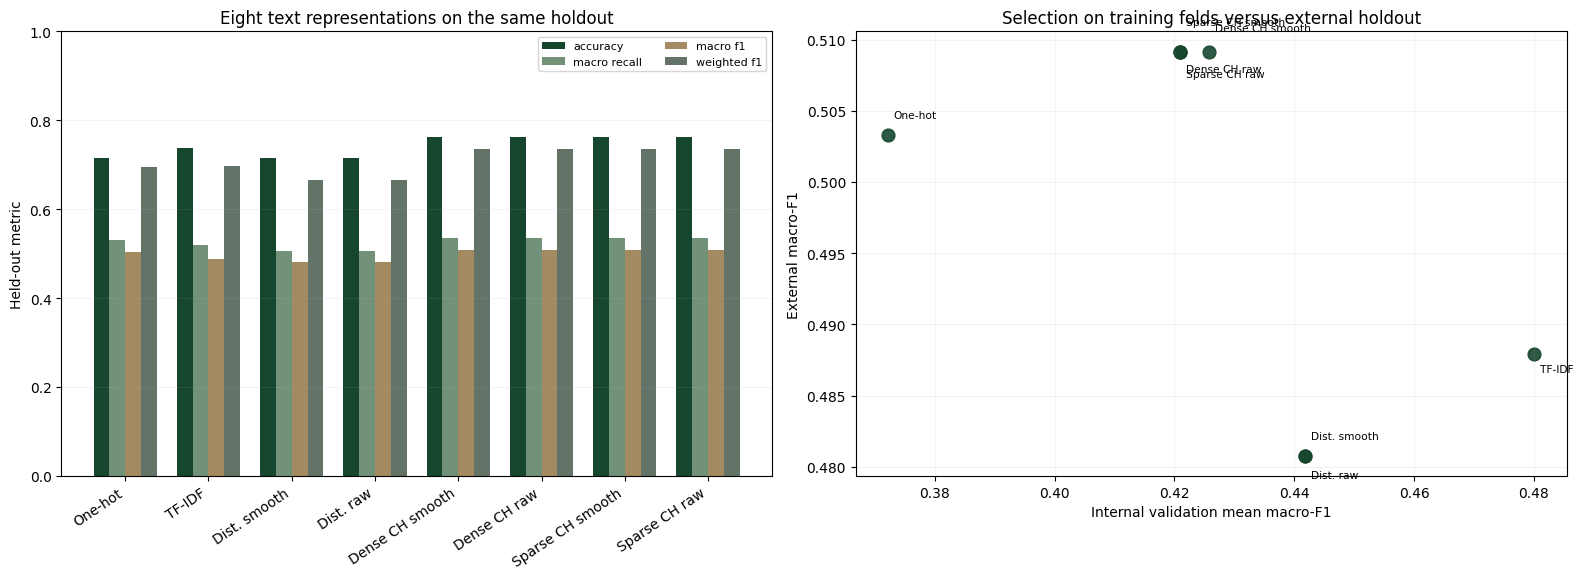

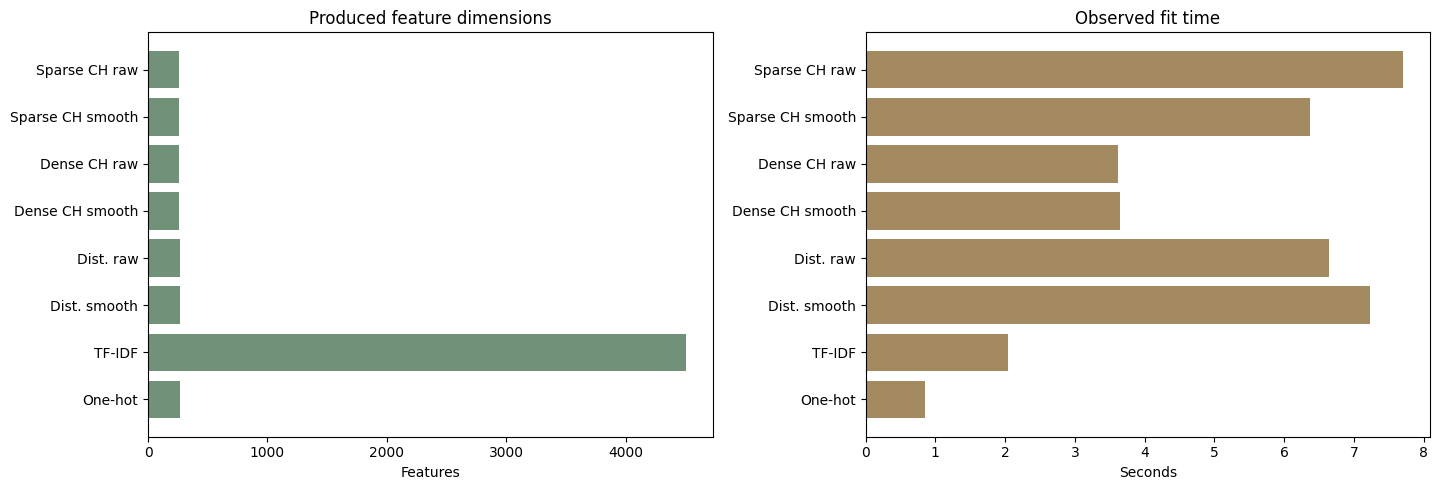

In [17]:
report_dir=Path(os.environ.get('CBS_OCCUPATION_OUTPUT_DIR','occupation_classification_outputs'))
report_dir.mkdir(parents=True,exist_ok=True)
labels=['One-hot','TF-IDF','Dist. smooth','Dist. raw',
        'Dense CH smooth','Dense CH raw','Sparse CH smooth','Sparse CH raw']
metrics_to_plot=['accuracy','macro_recall','macro_f1','weighted_f1']
fig,axes=plt.subplots(1,2,figsize=(16.0,5.9))
ind=np.arange(len(labels));width=.19
for k,m in enumerate(metrics_to_plot):
    axes[0].bar(ind+(k-1.5)*width,external[m].to_numpy(),width,
        label=m.replace('_',' '),color=list(PALETTE.values())[[0,1,4,2][k]])
axes[0].set(ylim=(0,1),ylabel='Held-out metric',title='Eight text representations on the same holdout')
axes[0].set_xticks(ind,labels,rotation=34,ha='right')
axes[0].grid(axis='y',alpha=.14)
axes[0].legend(fontsize=8,ncol=2)
rank=inner_summary.set_index('model').loc[external.model]
axes[1].scatter(rank.macro_f1_mean.to_numpy(),external.macro_f1.to_numpy(),
                 color=PALETTE['blue'],s=85,alpha=.9)
offsets=[(4,12),(4,-13),(4,12),(4,-16),(4,15),(4,-15),(4,19),(4,-18)]
for i,tag in enumerate(labels):
    axes[1].annotate(tag,(rank.macro_f1_mean.iloc[i],external.macro_f1.iloc[i]),
                     xytext=offsets[i],textcoords='offset points',fontsize=7.7)
axes[1].set(xlabel='Internal validation mean macro-F1',ylabel='External macro-F1',
            title='Selection on training folds versus external holdout')
axes[1].grid(alpha=.14)
fig.tight_layout()
fig.savefig(report_dir/'occupation_eight_models_comparison.png',dpi=175,bbox_inches='tight')
plt.show()

fig,axs=plt.subplots(1,2,figsize=(14.5,5.0))
axs[0].barh(labels,external.n_features,color=PALETTE['teal'])
axs[0].set(title='Produced feature dimensions',xlabel='Features')
axs[1].barh(labels,external.fit_sec,color=PALETTE['orange'])
axs[1].set(title='Observed fit time',xlabel='Seconds')
fig.tight_layout()
fig.savefig(report_dir/'occupation_feature_costs.png',dpi=165,bbox_inches='tight')
plt.show()

## 18. מדדים לפי מחלקה, טעויות ושאלת המשמעות התפעולית

לא מחליפים precision ב-recall או ההפך. הדוח כולל כל מחלקה שהופיעה בנתוני הבדיקה או נחזתה, ואת תמיכת המחלקה (`support`). מספר תוויות הבדיקה שלא נצפו באימון הוא **מגבלה מבנית**, ולא שגיאה שאפשר לתקן בהנדסת טקסט בלבד.

Classification report: internally selected model / external holdout
              precision    recall  f1-score   support

        1212       0.00      0.00      0.00         1
        2120       0.00      0.00      0.00         0
        2330       0.00      0.00      0.00         1
        2342       1.00      1.00      1.00         1
        2412       0.00      0.00      0.00         1
        2511       0.00      0.00      0.00         2
        2512       0.00      0.00      0.00         0
        2514       0.33      1.00      0.50         1
        2631       1.00      1.00      1.00         1
        2635       1.00      1.00      1.00         1
        3122       1.00      1.00      1.00         2
        3312       0.00      0.00      0.00         1
        3323       0.00      0.00      0.00         2
        3334       0.00      0.00      0.00         1
        3512       0.00      0.00      0.00         1
        5120       1.00      1.00      1.00         4
        5131 

,occupation_code,precision,recall,f1-score,support
19,5223,0.857,1.0,0.923,6.0
15,5120,1.000,1.0,1.000,4.0
25,9112,1.000,1.0,1.000,4.0
21,5322,0.600,1.0,0.750,3.0
22,5412,1.000,1.0,1.000,3.0
5,2511,0.000,0.0,0.000,2.0
12,3323,0.000,0.0,0.000,2.0
10,3122,1.000,1.0,1.000,2.0
16,5131,1.000,1.0,1.000,2.0
0,1212,0.000,0.0,0.000,1.0


Disagreements: 11


,ID,actual,selected,seen_in_train,correct
3,25,3323,5322,False,False
15,88,3323,5322,False,False
25,139,1212,2120,False,False
26,140,2511,5142,True,False
27,144,3512,2512,True,False
32,166,2511,5142,True,False
33,174,2330,2514,False,False
35,177,5222,5230,False,False
36,180,3334,5223,False,False
38,184,2412,3512,False,False


Selected only correct: 2 | One-hot only correct: 1 | Both correct: 29


Paired bootstrap 95% interval, macro-F1 selected minus one-hot: [-0.075, 0.090]
Exploratory uncertainty only; not a production-population confidence interval.


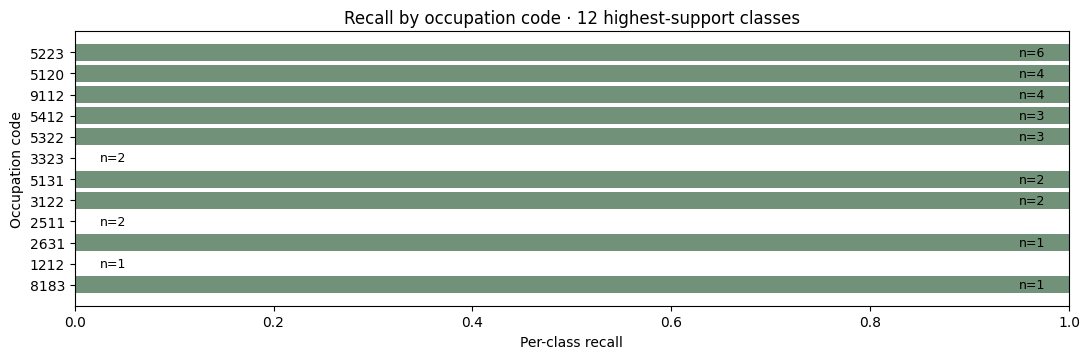

In [18]:
selected_pred=outer_predictions[SELECTED]
print('Classification report: internally selected model / external holdout')
print(classification_report(y_test,selected_pred,zero_division=0))
per_class=classification_report(y_test,selected_pred,zero_division=0,output_dict=True)
per_class_table=(pd.DataFrame(per_class).T.drop(index=['accuracy','macro avg','weighted avg'],errors='ignore')
                 .reset_index().rename(columns={'index':'occupation_code'}))
per_class_table['support']=pd.to_numeric(per_class_table.support)
display(per_class_table.sort_values(['support','recall'],ascending=[False,True]).head(30).round(3))

comparative_errors=pd.DataFrame({'ID':held_out.ID,'actual':held_out.given_code,
                                 'selected':selected_pred,
                                 'seen_in_train':held_out.class_seen_in_training})
comparative_errors['correct']=comparative_errors.actual.eq(comparative_errors.selected)
print('Disagreements:',int((~comparative_errors.correct).sum()))
display(comparative_errors.loc[~comparative_errors.correct].head(30))

# Paired holdout differences are diagnostic, not statistical proof on simulated labels.
base_pred=outer_predictions['One-hot: complete texts']
selected_correct=selected_pred==y_test.to_numpy()
base_correct=base_pred==y_test.to_numpy()
print('Selected only correct:',int(np.sum(selected_correct & ~base_correct)),
      '| One-hot only correct:',int(np.sum(base_correct & ~selected_correct)),
      '| Both correct:',int(np.sum(base_correct & selected_correct)))

# A small-sample paired bootstrap interval for the model-minus-one-hot macro-F1 difference.
rng=np.random.default_rng(SEED)
true=np.asarray(y_test,dtype=str)
boot=[]
for _ in range(800):
    sample=rng.integers(0,len(true),size=len(true))
    boot.append(f1_score(true[sample],selected_pred[sample],average='macro',zero_division=0)-
                f1_score(true[sample],base_pred[sample],average='macro',zero_division=0))
ci_low,ci_high=np.quantile(boot,[.025,.975])
print(f'Paired bootstrap 95% interval, macro-F1 selected minus one-hot: [{ci_low:.3f}, {ci_high:.3f}]')
print('Exploratory uncertainty only; not a production-population confidence interval.')

fig,ax=plt.subplots(figsize=(11,3.7))
important=per_class_table.sort_values('support',ascending=False).head(12).iloc[::-1]
ax.barh(important.occupation_code.astype(str),important.recall,color=PALETTE['teal'])
ax.set(xlim=(0,1),xlabel='Per-class recall',ylabel='Occupation code',
       title='Recall by occupation code · 12 highest-support classes')
for i,(_,row) in enumerate(important.iterrows()):
    ax.text(min(float(row.recall)+.025,.95),i,f'n={int(row.support)}',fontsize=9,va='center')
fig.tight_layout();fig.savefig(report_dir/'occupation_per_class_recall.png',dpi=175,bbox_inches='tight')
plt.show()

## 19. עקומות Calinski-Harabasz מלאות בארבע תצורות KMeans

בכל שדה טקסט מוצג גרף גדול אחד עם ארבע עקומות נפרדות של KMeans צפוף ושל MiniBatchKMeans דליל, עם החלקת IDF ובלעדיה. מוצגות כל נקודות K שנבדקו בפועל, ללא דילוגים, מ-2 ועד `min(1000,u-1)`, כאשר `u` הוא מספר וקטורי TF-IDF הייחודיים באימון. כאשר המספרים זהים, חלק מהעקומות חופפות. סימון ומקרא שונים מאפשרים לזהות את כל ארבע התצורות ללא שינוי מלאכותי של הציונים.

ציר K משתמש בסימוני מספרים שלמים בלבד. ציר המדד משתמש גם הוא בתוויות מספרים שלמים. ערכי Calinski-Harabasz עצמם הם מספרים ממשיים, ולכן טבלה מלאה מציגה את התוצאה המדויקת לכל K. הגרפים מציגים גם את K שנבחר ואת ציון המדד בכל אחת מארבע התצורות.

הציון הוא יחס שונות ולא מבחן מובהקות. ככל שמספר האשכולות מתקרב למספר הרשומות, פיזור האשכולות הפנימי יכול להיות קטן במיוחד, ולכן מקסימום בקצה הטווח אינו הוכחה לקיבוץ מקצועי מועיל.

Selected K and independently verified CH calculation


,field,model,n_distinct_values,chosen_k,ch_score,manual_ch,status
0,SugAvoda,CH dense KMeans smooth,64,63,7.025119,7.025119,kmeans
1,ShemMachlaka,CH dense KMeans smooth,50,49,4.131363,4.131363,kmeans
2,SugMachlaka,CH dense KMeans smooth,27,26,3.525076,3.525076,kmeans
3,EzoAvoda,CH dense KMeans smooth,67,66,13.979864,13.979864,kmeans
4,TeurPeula,CH dense KMeans smooth,24,23,4.956627,4.956627,kmeans
5,TeurTafkid,CH dense KMeans smooth,10,8,1.178493,1.178493,kmeans
6,SugAvoda,CH dense KMeans no smooth,64,63,6.567653,6.567653,kmeans
7,ShemMachlaka,CH dense KMeans no smooth,50,49,3.863888,3.863888,kmeans
8,SugMachlaka,CH dense KMeans no smooth,27,26,3.140001,3.140001,kmeans
9,EzoAvoda,CH dense KMeans no smooth,67,66,14.649345,14.649345,kmeans


Independent variance-ratio verification: 24 selected fits confirmed
FULL CALINSKI-HARABASZ SCORE MATRIX FOR SugAvoda


model,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
k,,,,
2,1.90982782,1.78087911,1.70033491,1.65658484
3,1.75134995,1.50477721,1.62870568,1.60447352
4,2.08607166,1.64260318,1.73599458,2.02614039
5,2.05453175,1.86959264,1.90988942,1.70836327
6,1.83010715,1.67244101,2.05421593,1.92910563
7,1.86127638,1.68147760,1.82468038,1.90867797
8,1.88802649,1.86979381,1.81865861,1.78720962
9,1.83023517,1.69108577,1.93265149,1.96958365
10,1.89491651,1.84278328,2.06675171,1.98251240


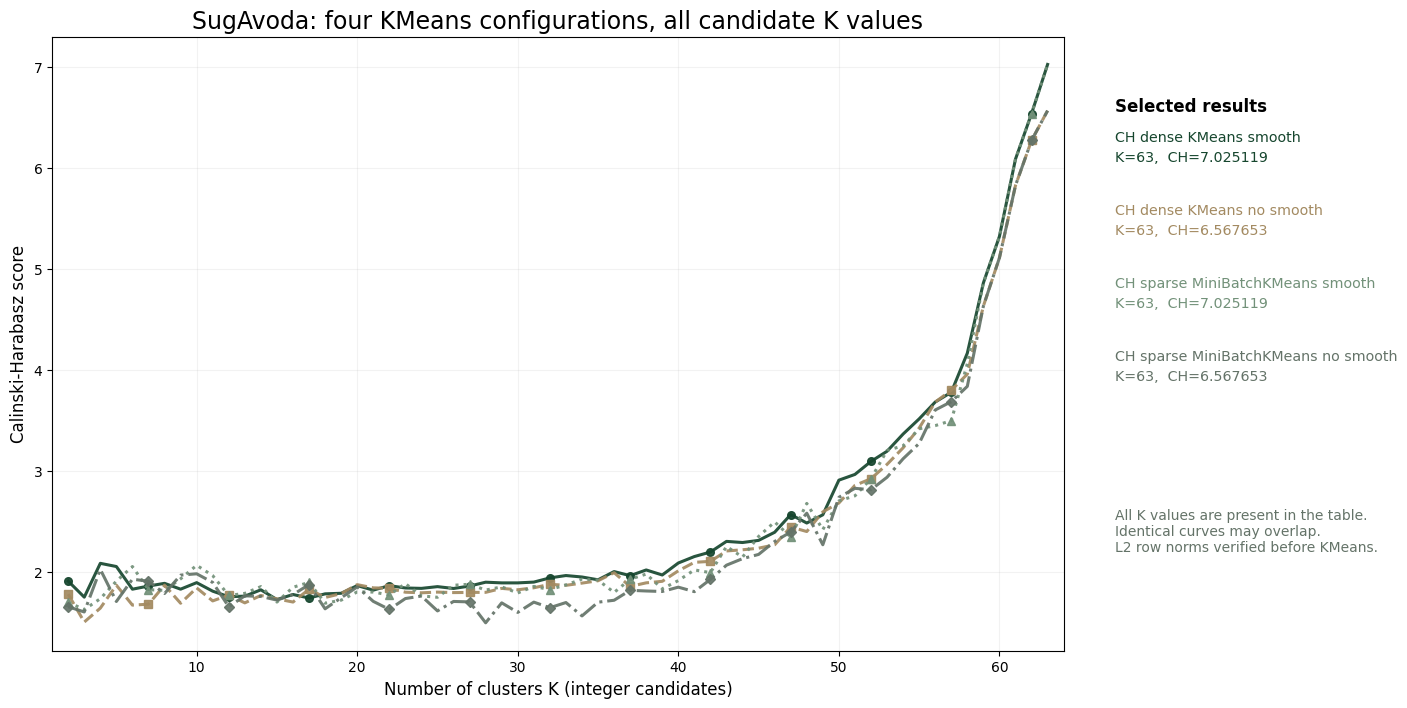

FULL CALINSKI-HARABASZ SCORE MATRIX FOR ShemMachlaka


model,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
k,,,,
2,1.38772835,1.35400557,1.37095195,1.35352196
3,1.35661234,1.33026415,1.17316535,1.30214732
4,1.32057825,1.32274806,1.47491713,1.42137110
5,1.32666915,1.32169274,1.34445111,1.19919549
6,1.35387141,1.31584595,1.29276062,1.32429035
7,1.32341231,1.31594878,1.40934515,1.14249379
8,1.40125272,1.33686635,1.31489092,1.30001388
9,1.44002144,1.32211078,1.18908749,1.24441968
10,1.39150759,1.33855018,1.30383521,1.27238792


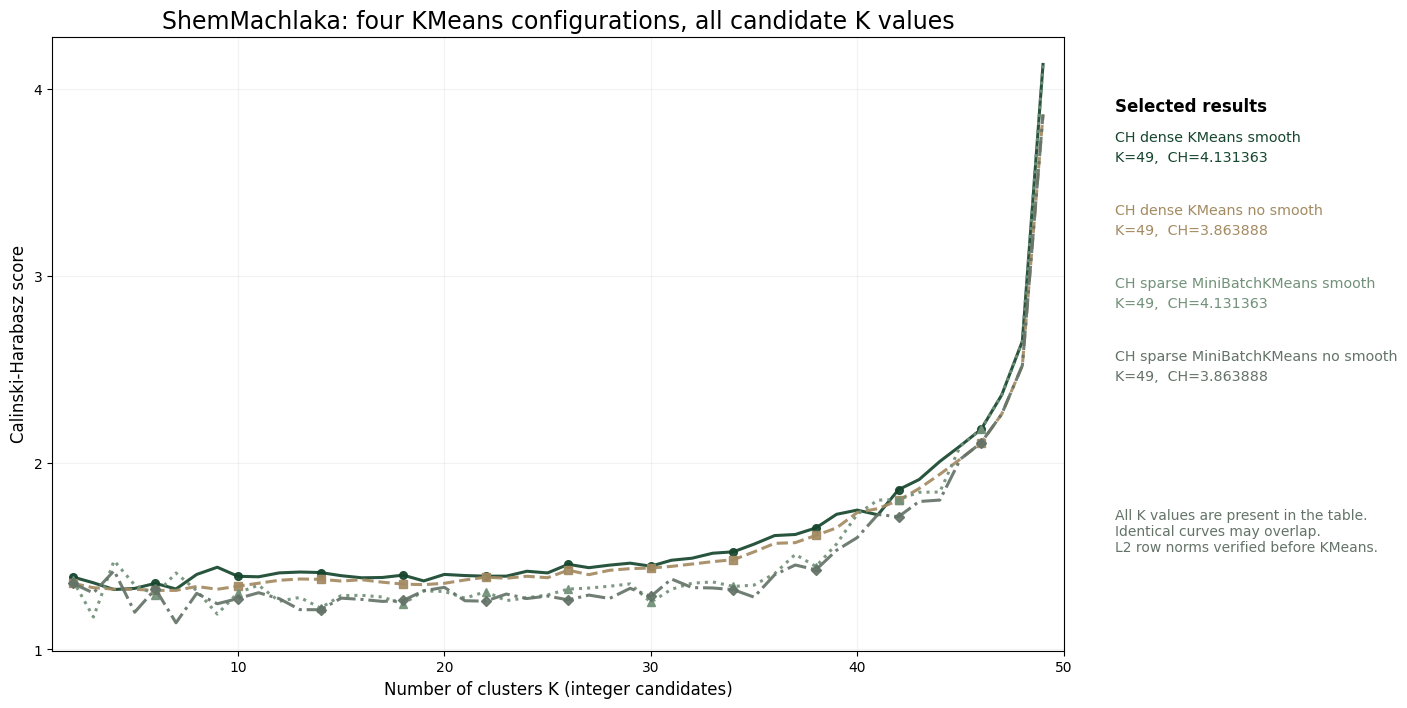

FULL CALINSKI-HARABASZ SCORE MATRIX FOR SugMachlaka


model,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
k,,,,
2,1.60841519,1.41767145,1.47925594,1.44699454
3,1.44987162,1.40567710,1.32272955,1.30550641
4,1.31689617,1.32839530,1.13646196,1.10165405
5,1.36494932,1.39035118,1.35015891,1.37722130
6,1.34694603,1.33585760,1.29190118,1.22391873
7,1.37623544,1.35143361,1.24336957,1.26862136
8,1.38958316,1.37039363,1.22115881,1.21572506
9,1.37156860,1.35017761,1.21136458,1.18474313
10,1.41591963,1.36681211,1.32728290,1.29152559


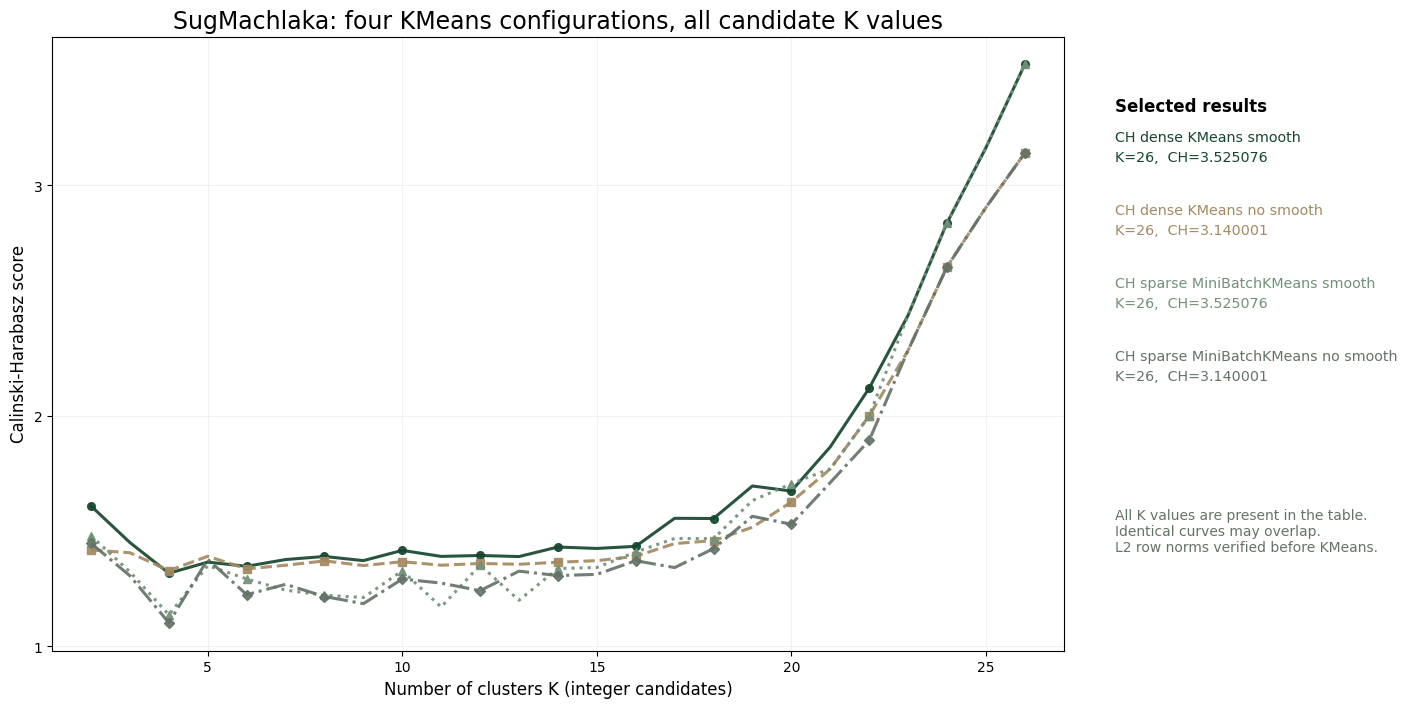

FULL CALINSKI-HARABASZ SCORE MATRIX FOR EzoAvoda


model,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
k,,,,
2,1.68158671,1.64791370,1.84201794,1.57194440
3,1.82263943,1.72543649,1.79513159,2.06841552
4,1.65161818,1.65547672,1.70110214,1.69976501
5,1.81804100,1.70787320,1.88933108,1.75839685
6,1.77082407,1.69754093,1.56638710,1.70136914
7,1.82711087,1.77869954,1.88476378,1.81274214
8,1.79495281,1.72842479,1.87100922,1.83904474
9,1.77293380,1.72446950,1.88067104,1.81027035
10,1.82141076,1.79201542,1.97975165,1.75849915


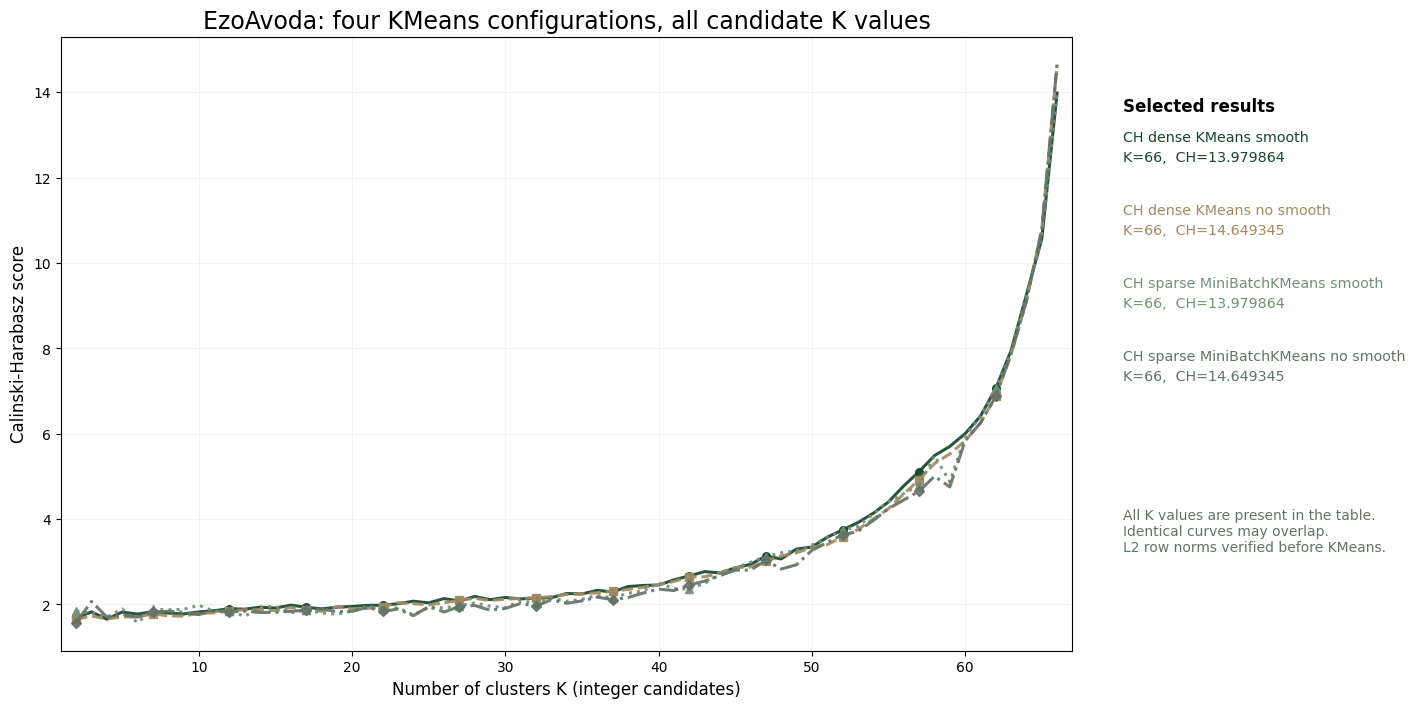

FULL CALINSKI-HARABASZ SCORE MATRIX FOR TeurPeula


model,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
k,,,,
2,1.33872208,1.29798514,1.37494708,1.00511424
3,1.28411248,1.25844265,1.26698707,1.23839991
4,1.44759937,1.40728813,1.19718147,1.18026944
5,1.45707617,1.38394011,1.17193354,1.15544655
6,1.44306618,1.40703564,1.16825759,1.11911641
7,1.45048496,1.41477132,1.26375755,1.19909688
8,1.49466720,1.44051228,1.38539712,1.31849800
9,1.50123796,1.46685632,1.33372944,1.26440611
10,1.49661865,1.46211865,1.25175653,1.24140749


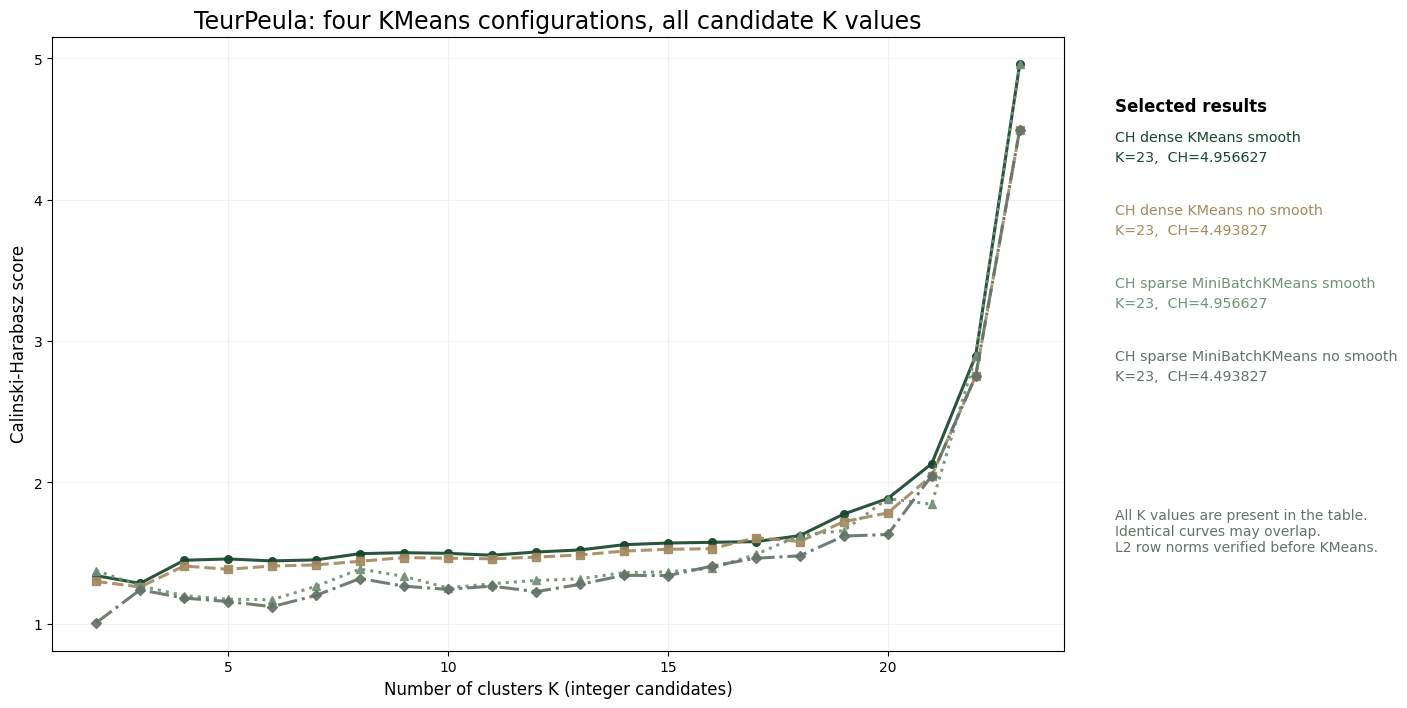

FULL CALINSKI-HARABASZ SCORE MATRIX FOR TeurTafkid


model,CH dense KMeans smooth,CH dense KMeans no smooth,CH sparse MiniBatchKMeans smooth,CH sparse MiniBatchKMeans no smooth
k,,,,
2,1.15165478,1.12817166,1.03838037,1.03134844
3,1.13248283,1.10343294,1.05540532,1.04567192
4,1.10669277,1.08106660,1.09631242,1.08106660
5,1.12442104,1.10458762,1.05681884,1.06302104
6,1.10188019,1.08571641,1.07062425,1.04651263
7,1.11921023,1.11113170,1.08642693,1.07097695
8,1.17849345,1.14816034,1.09290355,1.07880249
9,1.17539092,1.14409659,1.17539092,1.14409659


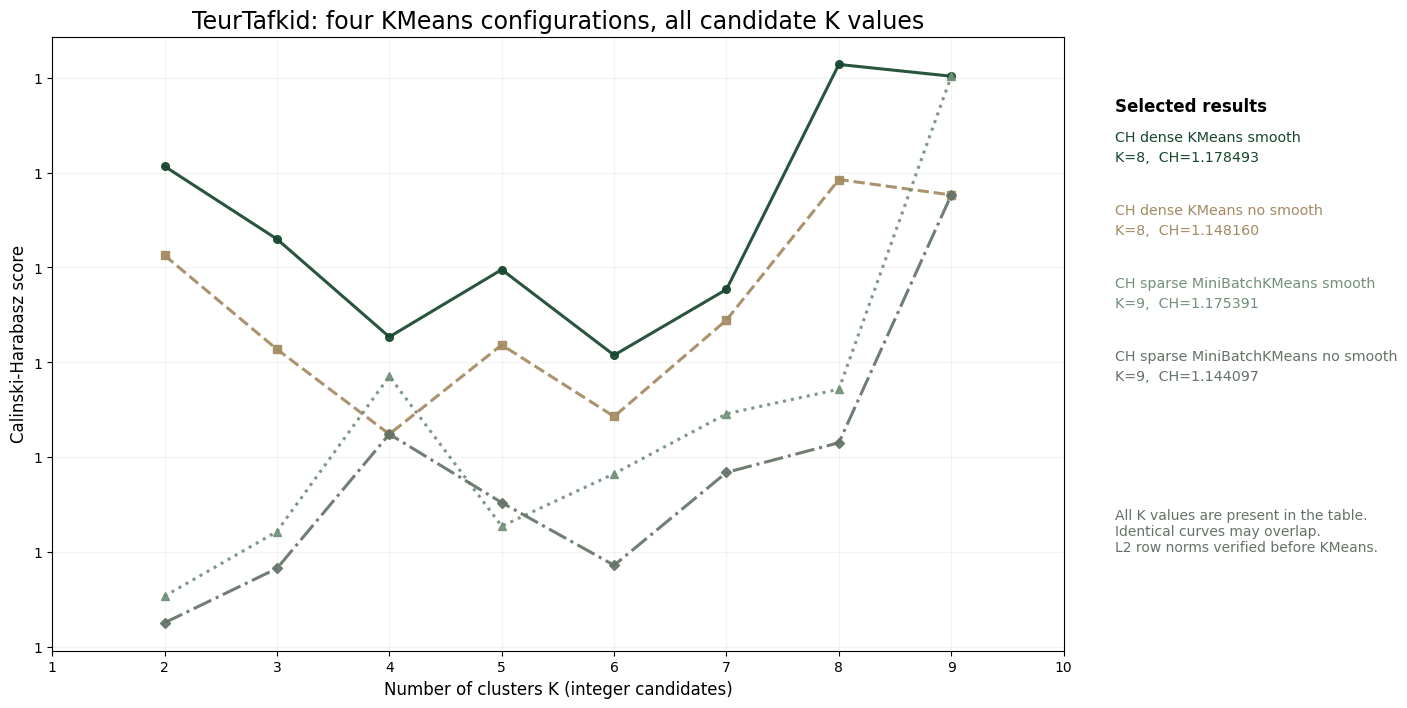

K candidate completeness: all four configurations use identical exhaustive integer ranges.


In [19]:
from matplotlib.ticker import MultipleLocator,MaxNLocator,FormatStrFormatter

CLUSTER_VERSIONS=[
 ('CH dense KMeans smooth',True,'dense',PALETTE['blue'],'solid','o'),
 ('CH dense KMeans no smooth',False,'dense',PALETTE['orange'],'dashed','s'),
 ('CH sparse MiniBatchKMeans smooth',True,'sparse',PALETTE['teal'],'dotted','^'),
 ('CH sparse MiniBatchKMeans no smooth',False,'sparse',PALETTE['gray'],'dashdot','D'),
]
all_curves=[]
selected_k=[]
for model_name,smoothing,representation,_,_,_ in CLUSTER_VERSIONS:
    branch=outer_models[model_name].named_steps['represent'].named_transformers_['cluster_text']
    encoder=branch.named_steps['onehot']
    cluster=branch.named_steps['assign']
    nominal=cluster.transform(X_test[APPROVED_TEXT])
    onehot=encoder.transform(nominal)
    vals=onehot.toarray() if hasattr(onehot,'toarray') else np.asarray(onehot)
    assert set(np.unique(vals)).issubset({0,1})
    assert nominal.dtype==object
    assert cluster.representation==representation
    assert cluster.smooth_idf==smoothing
    assert np.allclose(cluster.matrix_checks_table_.min_L2,1,atol=1e-9)
    assert np.allclose(cluster.matrix_checks_table_.max_L2,1,atol=1e-9)
    a=cluster.score_table_.copy();a['model']=model_name
    b=cluster.selection_table_.copy();b['model']=model_name
    all_curves.append(a)
    selected_k.append(b)
ch_curves=pd.concat(all_curves,ignore_index=True)
k_selected=pd.concat(selected_k,ignore_index=True)
print('Selected K and independently verified CH calculation')
display(k_selected[['field','model','n_distinct_values','chosen_k',
                    'ch_score','manual_ch','status']].round(6))
finite=k_selected.dropna(subset=['ch_score','manual_ch'])
assert np.allclose(finite.ch_score,finite.manual_ch,rtol=1e-7,atol=1e-7)
print('Independent variance-ratio verification:',len(finite),'selected fits confirmed')

# Use six full-size figures, never a grid of small subplots.
for field in APPROVED_TEXT:
    data=ch_curves.loc[ch_curves.field.eq(field)].copy()
    scores=data.pivot(index='k',columns='model',values='ch')
    scores=scores.reindex(columns=[name for name,*_ in CLUSTER_VERSIONS])
    print('FULL CALINSKI-HARABASZ SCORE MATRIX FOR',field)
    with pd.option_context('display.max_rows',110,'display.max_columns',10,
                           'display.float_format',lambda value:f'{value:.8f}'):
        display(scores)
    safe=field.replace('/','_')
    scores.to_csv(report_dir/f'occupation_ch_scores_{safe}.csv',
                  encoding='utf-8-sig',float_format='%.15g')
    fig,ax=plt.subplots(figsize=(17,8.3))
    fig.subplots_adjust(right=.72,bottom=.14,top=.88)
    kmax=int(scores.index.max())
    for name,smooth,representation,color,style,marker in CLUSTER_VERSIONS:
        sample=data.loc[data.model.eq(name)].sort_values('k')
        ax.plot(sample.k,sample.ch,color=color,linestyle=style,
                marker=marker,markevery=max(1,len(sample)//12),
                markersize=5.5,linewidth=2.2,label=name,alpha=.92)
    step=1 if kmax<=15 else 5 if kmax<=45 else 10
    ax.xaxis.set_major_locator(MultipleLocator(step))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=8,integer=True))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.set_xlim(1,kmax+1)
    ax.set_xlabel('Number of clusters K (integer candidates)',fontsize=12)
    ax.set_ylabel('Calinski-Harabasz score',fontsize=12)
    ax.set_title(f'{field}: four KMeans configurations, all candidate K values',fontsize=17)
    ax.grid(True,alpha=.16)
    selection=k_selected.loc[k_selected.field.eq(field)].set_index('model')
    fig.text(.75,.79,'Selected results',fontsize=12,fontweight='bold')
    for j,(name,smooth,representation,color,_,_) in enumerate(CLUSTER_VERSIONS):
        row=selection.loc[name]
        score=float(row.ch_score)
        kval=int(row.chosen_k)
        fig.text(.75,.73-j*.088,f'{name}\nK={kval},  CH={score:.6f}',
                 fontsize=10.3,color=color,linespacing=1.5)
    fig.text(.75,.26,'All K values are present in the table.\n'
             'Identical curves may overlap.\n'
             'L2 row norms verified before KMeans.',
             fontsize=10,color=PALETTE['gray'])
    fig.savefig(report_dir/f'occupation_ch_four_config_{safe}.png',
                dpi=175,bbox_inches='tight')
    plt.show()

assert len(k_selected)==4*len(APPROVED_TEXT)
assert ch_curves.groupby(['field','model']).size().min()>0
for field in APPROVED_TEXT:
    field_curves=ch_curves.loc[ch_curves.field.eq(field)]
    u=int(k_selected.loc[k_selected.field.eq(field),'n_distinct_values'].iloc[0])
    expected=list(range(2,min(1000,u-1)+1))
    for model_name in [row[0] for row in CLUSTER_VERSIONS]:
        observed=field_curves.loc[field_curves.model.eq(model_name),'k'].tolist()
        assert observed==expected,(field,model_name,expected,observed)
print('K candidate completeness: all four configurations use identical exhaustive integer ranges.')


## 20. בדיקת תוכן האשכולות

תיאורי עבודה הקשורים לפיתוח תוכנה נבדקים בכל ארבע תצורות KMeans. הציונים מתארים הפרדה גאומטרית, ולא קובעים האם תיאורים נבדלים מתייחסים לאותו מקצוע. שיוך התיאורים לשדות, לאשכולות ולקודי היעד מוצג לביקורת מקצועית.

In [20]:
software_pattern=r'תוכנ|מתכנת|מפתח|פיתוח'
review_members=[]
for model_key,_,_,_,_,_ in CLUSTER_VERSIONS:
    cluster=(outer_models[model_key].named_steps['represent']
             .named_transformers_['cluster_text'].named_steps['assign'])
    for field in APPROVED_TEXT:
        for value,cluster_id in cluster.models_[field]['lookup'].items():
            if re.search(software_pattern,value,flags=re.IGNORECASE):
                review_members.append({'model':model_key,'field':field,
                           'observed_description':value,'cluster':cluster_id})
member_audit=pd.DataFrame(review_members,columns=[
    'model','field','observed_description','cluster'])
print('Programming-related descriptions assessed:',len(member_audit))
for field in ['EzoAvoda','SugAvoda','TeurTafkid']:
    print('Field:',field)
    display(member_audit.loc[member_audit.field.eq(field)].head(40))
if len(member_audit):
    print('Distinct cluster IDs containing programming-related descriptions')
    display(member_audit.groupby(['model','field'])['cluster'].nunique().to_frame('clusters'))

Programming-related descriptions assessed: 84
Field: EzoAvoda


,model,field,observed_description,cluster
9,CH dense KMeans smooth,EzoAvoda,"מהנדס תוכנה, מנהל צוות עובדים",cluster_000
10,CH dense KMeans smooth,EzoAvoda,"מהנדס תוכנה, מנהל צוות פיתוח",cluster_063
11,CH dense KMeans smooth,EzoAvoda,מנהל פיתוח,cluster_016
12,CH dense KMeans smooth,EzoAvoda,מפתח,cluster_005
13,CH dense KMeans smooth,EzoAvoda,מפתח אפליקציות,cluster_051
14,CH dense KMeans smooth,EzoAvoda,מפתח תוכנה,cluster_054
15,CH dense KMeans smooth,EzoAvoda,מתכנת,cluster_015
16,CH dense KMeans smooth,EzoAvoda,"ר""ש פיתוח",cluster_056
30,CH dense KMeans no smooth,EzoAvoda,"מהנדס תוכנה, מנהל צוות עובדים",cluster_000
31,CH dense KMeans no smooth,EzoAvoda,"מהנדס תוכנה, מנהל צוות פיתוח",cluster_063


Field: SugAvoda


,model,field,observed_description,cluster
0,CH dense KMeans smooth,SugAvoda,"הייטק, פיתוח תוכנה",cluster_001
1,CH dense KMeans smooth,SugAvoda,מנהל פיתוח,cluster_050
2,CH dense KMeans smooth,SugAvoda,פיתוח מוצרי תוכנה,cluster_057
3,CH dense KMeans smooth,SugAvoda,פיתוח תוכנה,cluster_021
4,CH dense KMeans smooth,SugAvoda,פיתוח תוכנה לצ'יפים,cluster_059
5,CH dense KMeans smooth,SugAvoda,פיתוח תכנה,cluster_058
21,CH dense KMeans no smooth,SugAvoda,"הייטק, פיתוח תוכנה",cluster_001
22,CH dense KMeans no smooth,SugAvoda,מנהל פיתוח,cluster_050
23,CH dense KMeans no smooth,SugAvoda,פיתוח מוצרי תוכנה,cluster_051
24,CH dense KMeans no smooth,SugAvoda,פיתוח תוכנה,cluster_011


Field: TeurTafkid


,model,field,observed_description,cluster
20,CH dense KMeans smooth,TeurTafkid,פיתוח תכנה,cluster_007
41,CH dense KMeans no smooth,TeurTafkid,פיתוח תכנה,cluster_007
62,CH sparse MiniBatchKMeans smooth,TeurTafkid,פיתוח תכנה,cluster_008
83,CH sparse MiniBatchKMeans no smooth,TeurTafkid,פיתוח תכנה,cluster_008


Distinct cluster IDs containing programming-related descriptions


clusters
model                               field                 
CH dense KMeans no smooth           EzoAvoda             8
                                    ShemMachlaka         2
                                    SugAvoda             6
                                    SugMachlaka          1
                                    TeurPeula            3
                                    TeurTafkid           1
CH dense KMeans smooth              EzoAvoda             8
                                    ShemMachlaka         2
                                    SugAvoda             6
                                    SugMachlaka          1
                                    TeurPeula            3
                                    TeurTafkid           1
CH sparse MiniBatchKMeans no smooth EzoAvoda             8
                                    ShemMachlaka         2
                                    SugAvoda             6
                                    SugMachlaka          1
                                    TeurPeula            3
                                    TeurTafkid           1
CH sparse MiniBatchKMeans smooth    EzoAvoda             8
                                    ShemMachlaka         2
                                    SugAvoda             6
                                    SugMachlaka          1
                                    TeurPeula            3
                                    TeurTafkid           1

## 21. הצעת קודים לרשומות עם סימול חלקי

תוויות המכילות `X` מוחרגות מאימון המודלים ומחישוב מדדי ההערכה. לאחר קביעת השיטה המועדפת והשלמת ההערכה, מאמנים אותה מחדש על כל 191 הרשומות בעלות הסימול המלא ומפיקים הצעות לסימול עבור תשע הרשומות החלקיות. אלו הצעות לסקירת סמלן ולא החלטות אוטומטיות. ציוני הסתברות שאינם מכוילים אינם מפורשים כהסתברות לתחזית נכונה.

In [21]:
selected_kind,_,selected_smooth=next((k,name,s) for k,name,s in VARIANTS if name==SELECTED)
review_fit=build_candidate(selected_kind,selected_smooth).fit(X,y)
review_proposals=review_fit.predict(model_features(partial))
review_table=pd.DataFrame({'ID':partial['ID'].astype(int).to_numpy(),
                           'partially_coded_original':partial[TARGET].astype(str).to_numpy(),
                           'suggested_complete_code':review_proposals,
                           'operational_status':'human_coder_review'})
assert len(review_table)==9
print('Suggested occupation codes from the selected model, fitted on fully coded records:')
display(review_table)
print('Source workbook unchanged. These are model suggestions, not verified occupation codes.')

Suggested occupation codes from the selected model, fitted on fully coded records:


,ID,partially_coded_original,suggested_complete_code,operational_status
0,18,1XXX,2511,human_coder_review
1,45,XXXX,2511,human_coder_review
2,50,1XXX,2511,human_coder_review
3,81,1XXX,2511,human_coder_review
4,108,XXXX,2511,human_coder_review
5,113,1XXX,2511,human_coder_review
6,142,XXXX,5223,human_coder_review
7,165,335X,3354,human_coder_review
8,193,XXXX,5223,human_coder_review


Source workbook unchanged. These are model suggestions, not verified occupation codes.


## 22. מסקנות והצעה להטמעה

**בחירת השיטה:** הבחירה מבוססת על ממוצע Macro-F1 באימות פנימי מקובץ. מוצגים גם מדדי הבדיקה החיצונית, אך הם אינם משמשים לשינוי הבחירה בדיעבד.

**השוואת הייצוגים:** כל שמונה השיטות משתמשות באותו מסווג ובאותם שדות שאינם טקסט. ארבע תצורות משלבות שתי הגדרות של החלקת IDF עם KMeans על קלט Dense או MiniBatchKMeans על קלט Sparse CSR. בכל התצורות בוצע נרמול L2 לפני KMeans ובוצעו כל מספרי K בין 2 לבין המינימום של 1000 ומספר ערכי הטקסט השונים פחות אחד.

**משמעות מדד CH:** המדד בוחן יחס שונות בין אשכולות ובתוכם. ריבוי אשכולות בקצה הטווח עשוי להגדיל את הציון בלי לצמצם באופן משמעותי את מספר תיאורי המקצוע. בחינת קיבוץ מועיל דורשת גם בדיקת חברי אשכולות ונתוני אמת נוספים.

**מגבלות הנתונים:** אין מזהה משתתף המקשר שידורים חוזרים ואין תאריך שידור. הסימולים אינם תוויות אמת מאומתות, יש מחלקות נדירות, ואין מידע מלא על זמינות כל שדה בזמן החיזוי. מדדי הסימולציה אינם אומדן דיוק של מערכת תפעולית.

**הטמעה:** יש לאמת סימולים מול סמלנים מקצועיים, לקבל מזהי משתתף וגרסאות, לבצע אימות לפי זמן ומשתתף, ולהשתמש בסקירה אנושית במקרים לא ברורים.

### מקורות מקצועיים
- [scikit-learn KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [scikit-learn MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html)
- [scikit-learn TF-IDF and L2](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)
- [scikit-learn Calinski-Harabasz](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html)
- [scikit-learn OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [scikit-learn data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)


In [22]:
# Final reproducibility and handoff: all comparisons are saved as human-readable data.
import json
results_record={
 'source_sha256':actual_hash,'python_version':sys.version.split()[0],
 'pandas_version':pd.__version__,'sklearn_version':sklearn.__version__,
 'train_rows':len(X_train),'holdout_rows':len(X_test),
 'unseen_holdout_labels':int((~y_test.isin(set(y_train))).sum()),
 'selected_on_inner_validation':SELECTED,
 'inner_models':inner_summary[['model','macro_f1_mean','macro_recall_mean',
                               'weighted_f1_mean','accuracy_mean']].to_dict('records'),
 'outer_models':external[['model','correct','accuracy','macro_recall',
                           'macro_f1','weighted_f1']].to_dict('records'),
 'bootstrap_selected_vs_onehot_macro_f1':[float(ci_low),float(ci_high)],
 'cluster_k':k_selected.replace({np.nan:None}).to_dict('records'),
 'tfidf_matrix_checks':matrix_audit.to_dict('records'),
 'cluster_score_records':len(ch_curves),
 'limitations':['simulated data','manual-label uncertainty',
                'participant linkage unavailable','novel occupation codes'],
}
(report_dir/'occupation_results.json').write_text(
    json.dumps(results_record,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
external.to_csv(report_dir/'occupation_external_models.csv',index=False,encoding='utf-8-sig')
inner_results.to_csv(report_dir/'occupation_inner_validation.csv',index=False,encoding='utf-8-sig')
held_out.to_csv(report_dir/'occupation_holdout_predictions.csv',index=False,encoding='utf-8-sig')
review_table.to_csv(report_dir/'occupation_partial_code_review.csv',index=False,encoding='utf-8-sig')
print('REPORT COMPLETE | Internally selected model:',SELECTED)
print('All 18 columns audited | Eight methods evaluated | Raw dataset unchanged')
print('CH choices, complete K curves, held-out predictions and findings available in',report_dir)

REPORT COMPLETE | Internally selected model: Direct TF-IDF smooth
All 18 columns audited | Eight methods evaluated | Raw dataset unchanged
CH choices, complete K curves, held-out predictions and findings available in /mnt/data/_occupation_final_execution_outputs
